# Fig. 3 check: WorldCover37 XGB cap20000, Apr-Oct

This notebook uses the completed `worldcover37_besthp_20260510` XGB `cap_20000` test predictions.
It filters predictions to April-October and keeps the full 37-site site list in all summary views.
Rows without Apr-Oct test samples are retained as missing values instead of being dropped.


In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

RUN_ROOT = Path("/home/chaonan.ji/data/projects/ecospectra/output_data/traits_model/outputs/ablations/worldcover37_besthp_20260510/runs/exp1_data_size/baseline/cap_20000/worldcover37_global_grouped_seed42/xgb")
SITE_META_PATH = Path("/home/chaonan.ji/data/projects/ecospectra/input_data/filtered_sites.csv")
PAPER_ROOT = Path("/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective")
TABLE_DIR = PAPER_ROOT / "tables" / "fig3_worldcover37_xgb_cap20000_apr_oct"
FIG_DIR = PAPER_ROOT / "figures" / "generated" / "fig3_worldcover37_xgb_cap20000_apr_oct"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

TRAITS = ["LAI", "LMA", "Nitrogen", "Chlorophyll", "Lignin"]
MONTH_START, MONTH_END = 4, 10

sns.set_theme(style="whitegrid", context="paper", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.edgecolor": "#4c4c4c",
    "axes.linewidth": 0.8,
    "font.family": "DejaVu Sans",
})


## Load Apr-Oct XGB test predictions


In [2]:
def load_trait_predictions(trait):
    path = RUN_ROOT / trait / "test_predictions.csv"
    header = pd.read_csv(path, nrows=0).columns.tolist()
    true_col = next(col for col in header if col.startswith("true__"))
    pred_col = next(col for col in header if col.startswith("pred__"))
    usecols = [
        "event_id", "sample_id", "site_id", "year", "y", "x",
        "trait_time", "trait_time_index", true_col, pred_col,
    ]
    df = pd.read_csv(path, usecols=usecols)
    df["date"] = pd.to_datetime(df["trait_time"])
    df = df[df["date"].dt.month.between(MONTH_START, MONTH_END)].copy()
    df["trait"] = trait
    df = df.rename(columns={true_col: "true", pred_col: "pred"})
    return df[[
        "event_id", "sample_id", "site_id", "year", "date",
        "trait_time_index", "y", "x", "trait", "true", "pred",
    ]]

pred = pd.concat([load_trait_predictions(trait) for trait in TRAITS], ignore_index=True)

site_meta = (
    pd.read_csv(SITE_META_PATH)
    [["site_id", "site_name", "location_lat", "location_lon"]]
    .drop_duplicates("site_id")
    .sort_values("site_id")
)
site_order = site_meta["site_id"].tolist()
site_meta["site_label"] = site_meta["site_id"].map(lambda x: f"{int(x):02d}") + " " + site_meta["site_name"]

coverage = (
    pred.groupby(["site_id", "year"], as_index=False)
    .size()
    .rename(columns={"size": "n_predictions"})
)
coverage_wide = (
    coverage.pivot(index="site_id", columns="year", values="n_predictions")
    .reindex(site_order)
    .fillna(0)
    .astype(int)
    .reset_index()
    .merge(site_meta[["site_id", "site_name"]], on="site_id", how="left")
)
coverage_wide = coverage_wide[["site_id", "site_name"] + [c for c in coverage_wide.columns if isinstance(c, int)]]
coverage_wide.to_csv(TABLE_DIR / "coverage_by_site_year_apr_oct.csv", index=False)

print(f"Loaded {len(pred):,} Apr-Oct prediction rows across {pred['site_id'].nunique()} sites.")
print(f"Full site list: {len(site_order)} sites.")
missing_sites = sorted(set(site_order) - set(pred["site_id"].unique()))
print("Sites with no Apr-Oct test predictions:", missing_sites if missing_sites else "none")
display(coverage_wide)


Loaded 1,224,505 Apr-Oct prediction rows across 36 sites.
Full site list: 37 sites.
Sites with no Apr-Oct test predictions: [46]


,site_id,site_name,2022,2023,2024,2025
0,0,Neustift,14990,14785,15030,14915
1,2,Chamau,0,0,0,15090
2,3,Laegern,0,14885,0,14545
3,6,Dagowsee,10610,14730,14060,8360
4,7,Gebesee,0,0,15030,15280
5,9,Hainich,0,14855,15060,15070
6,10,Huetelmoor,14615,14965,15030,15095
7,11,Klingenberg,0,14975,0,0
8,13,Leinefelde,0,15080,14640,14765
9,15,Schechenfilz Nord,15520,15325,14860,11415


## Site-trait metrics


In [3]:
def metric_row(group):
    y_true = group["true"].to_numpy(dtype=float)
    y_pred = group["pred"].to_numpy(dtype=float)
    finite = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[finite]
    y_pred = y_pred[finite]
    n = int(y_true.size)
    if n == 0:
        return pd.Series({"n_valid": 0, "r2": np.nan, "rmse": np.nan, "nrmse_pct": np.nan, "bias": np.nan})
    rmse = float(np.sqrt(np.mean((y_pred - y_true) ** 2)))
    trait_range = float(np.nanmax(y_true) - np.nanmin(y_true))
    nrmse_pct = float(rmse / trait_range * 100.0) if trait_range > 0 else np.nan
    if np.unique(y_true).size > 1:
        ss_res = float(np.sum((y_true - y_pred) ** 2))
        ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    else:
        r2 = np.nan
    return pd.Series({
        "n_valid": n,
        "r2": r2,
        "rmse": rmse,
        "nrmse_pct": nrmse_pct,
        "bias": float(np.mean(y_pred - y_true)),
    })

metrics = pred.groupby(["site_id", "trait"], sort=False).apply(metric_row).reset_index()
full_index = pd.MultiIndex.from_product([site_order, TRAITS], names=["site_id", "trait"]).to_frame(index=False)
metrics = full_index.merge(metrics, on=["site_id", "trait"], how="left")
metrics["n_valid"] = metrics["n_valid"].fillna(0).astype(int)
metrics = metrics.merge(site_meta, on="site_id", how="left")
metrics.to_csv(TABLE_DIR / "site_trait_metrics_apr_oct.csv", index=False)

summary = (
    metrics.groupby("trait", as_index=False)
    .agg(
        sites_with_data=("n_valid", lambda s: int((s > 0).sum())),
        median_r2=("r2", "median"),
        median_nrmse_pct=("nrmse_pct", "median"),
        total_samples=("n_valid", "sum"),
    )
)
summary.to_csv(TABLE_DIR / "trait_metric_summary_apr_oct.csv", index=False)
display(summary)
display(metrics[["site_id", "site_name", "trait", "n_valid", "r2", "nrmse_pct", "rmse", "bias"]])


,trait,sites_with_data,median_r2,median_nrmse_pct,total_samples
0,Chlorophyll,36,0.389208,10.392127,244901
1,LAI,36,0.636087,9.352376,244901
2,LMA,36,0.547759,6.572636,244901
3,Lignin,36,0.523301,6.819397,244901
4,Nitrogen,36,0.493772,6.771895,244901


,site_id,site_name,trait,n_valid,r2,nrmse_pct,rmse,bias
0,0,Neustift,LAI,11944,0.615538,9.431873,0.469288,-0.020180
1,0,Neustift,LMA,11944,0.569750,6.199964,15.863433,-0.007682
2,0,Neustift,Nitrogen,11944,0.478121,4.974970,0.024728,-0.000012
3,0,Neustift,Chlorophyll,11944,0.344264,8.570747,3.428290,0.215903
4,0,Neustift,Lignin,11944,0.516362,6.287009,0.451939,0.017796
...,...,...,...,...,...,...,...,...
180,57,Bavarian Forest,LAI,11441,0.592854,9.442989,0.468194,0.004944
181,57,Bavarian Forest,LMA,11441,0.608898,6.715440,16.304471,0.070042
182,57,Bavarian Forest,Nitrogen,11441,0.562560,6.472194,0.021968,0.000189
183,57,Bavarian Forest,Chlorophyll,11441,0.429415,10.970489,3.536043,0.073746


## R2 and nRMSE heatmaps


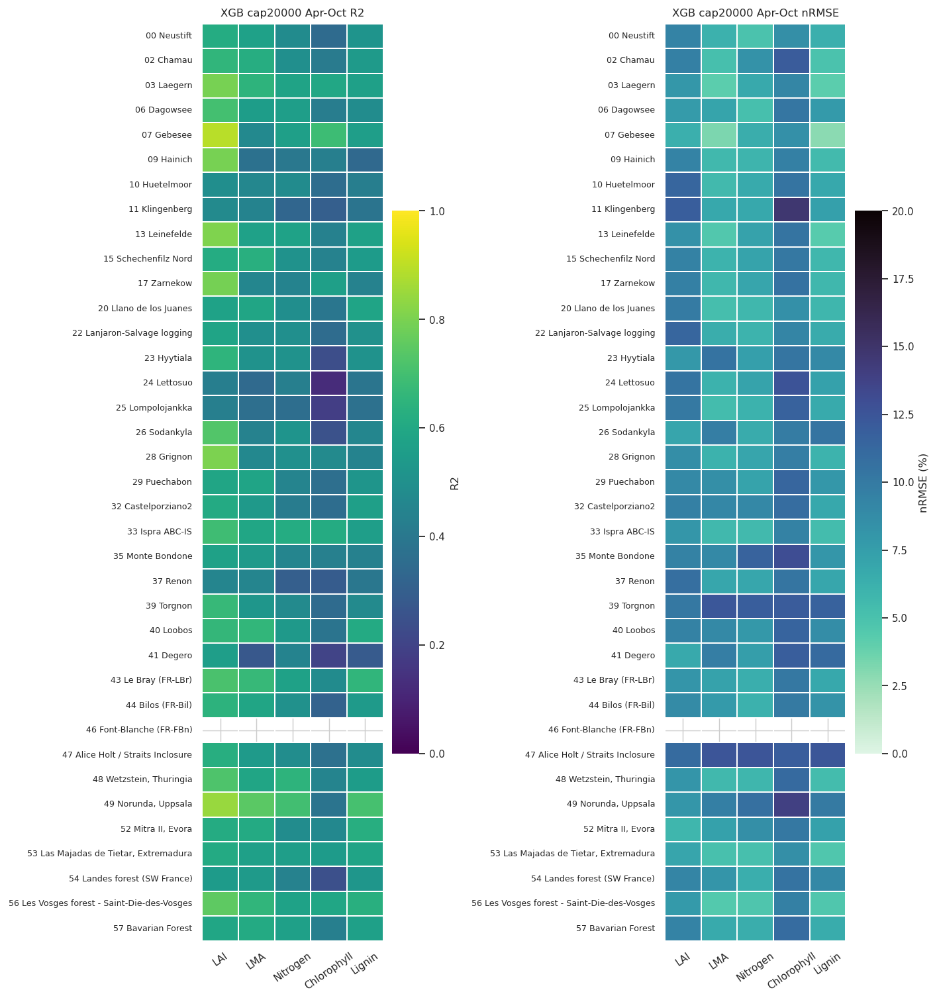

/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/figures/generated/fig3_worldcover37_xgb_cap20000_apr_oct/worldcover37_xgb_cap20000_apr_oct_skill_heatmaps.png
/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/figures/generated/fig3_worldcover37_xgb_cap20000_apr_oct/worldcover37_xgb_cap20000_apr_oct_skill_heatmaps.pdf


In [4]:
def heatmap_matrix(value_col):
    mat = metrics.pivot(index="site_label", columns="trait", values=value_col)
    site_labels = site_meta.set_index("site_id").loc[site_order, "site_label"].tolist()
    return mat.reindex(index=site_labels, columns=TRAITS)

r2_mat = heatmap_matrix("r2")
nrmse_mat = heatmap_matrix("nrmse_pct")

fig, axes = plt.subplots(1, 2, figsize=(10.8, 11.5), constrained_layout=True)
sns.heatmap(
    r2_mat,
    ax=axes[0],
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "R2"},
)
axes[0].set_title("XGB cap20000 Apr-Oct R2")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

upper = np.nanpercentile(nrmse_mat.to_numpy(dtype=float), 95)
vmax = max(20.0, float(upper)) if np.isfinite(upper) else 50.0
sns.heatmap(
    nrmse_mat,
    ax=axes[1],
    cmap="mako_r",
    vmin=0,
    vmax=vmax,
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "nRMSE (%)"},
)
axes[1].set_title("XGB cap20000 Apr-Oct nRMSE")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", labelsize=7)

heatmap_png = FIG_DIR / "worldcover37_xgb_cap20000_apr_oct_skill_heatmaps.png"
heatmap_pdf = FIG_DIR / "worldcover37_xgb_cap20000_apr_oct_skill_heatmaps.pdf"
fig.savefig(heatmap_png, bbox_inches="tight")
fig.savefig(heatmap_pdf, bbox_inches="tight")
plt.show()
print(heatmap_png)
print(heatmap_pdf)


## Daily median observed vs predicted values


In [5]:
daily = (
    pred.groupby(["site_id", "date", "trait"], as_index=False)
    .agg(
        true_median=("true", "median"),
        pred_median=("pred", "median"),
        true_q25=("true", lambda s: float(np.nanquantile(s, 0.25))),
        true_q75=("true", lambda s: float(np.nanquantile(s, 0.75))),
        pred_q25=("pred", lambda s: float(np.nanquantile(s, 0.25))),
        pred_q75=("pred", lambda s: float(np.nanquantile(s, 0.75))),
        n=("pred", "size"),
    )
    .merge(site_meta, on="site_id", how="left")
)
daily.to_csv(TABLE_DIR / "daily_site_trait_medians_apr_oct.csv", index=False)
display(daily.head())
print(f"Daily median table rows: {len(daily):,}")


,site_id,date,trait,true_median,pred_median,true_q25,true_q75,pred_q25,pred_q75,n,site_name,location_lat,location_lon,site_label
0,0,2022-06-27,Chlorophyll,34.427850,33.330673,32.424060,39.370186,32.568562,35.662437,105,Neustift,47.1167,11.3175,00 Neustift
1,0,2022-06-27,LAI,3.198069,3.114264,2.706886,3.549059,2.630064,3.397747,105,Neustift,47.1167,11.3175,00 Neustift
2,0,2022-06-27,LMA,75.574350,72.055733,69.256610,90.890884,67.011360,83.466354,105,Neustift,47.1167,11.3175,00 Neustift
3,0,2022-06-27,Lignin,1.096576,1.087572,0.921389,1.374632,0.939289,1.312480,105,Neustift,47.1167,11.3175,00 Neustift
4,0,2022-06-27,Nitrogen,0.187654,0.164697,0.167562,0.203783,0.150300,0.182902,105,Neustift,47.1167,11.3175,00 Neustift


Daily median table rows: 1,140


## Coverage heatmap


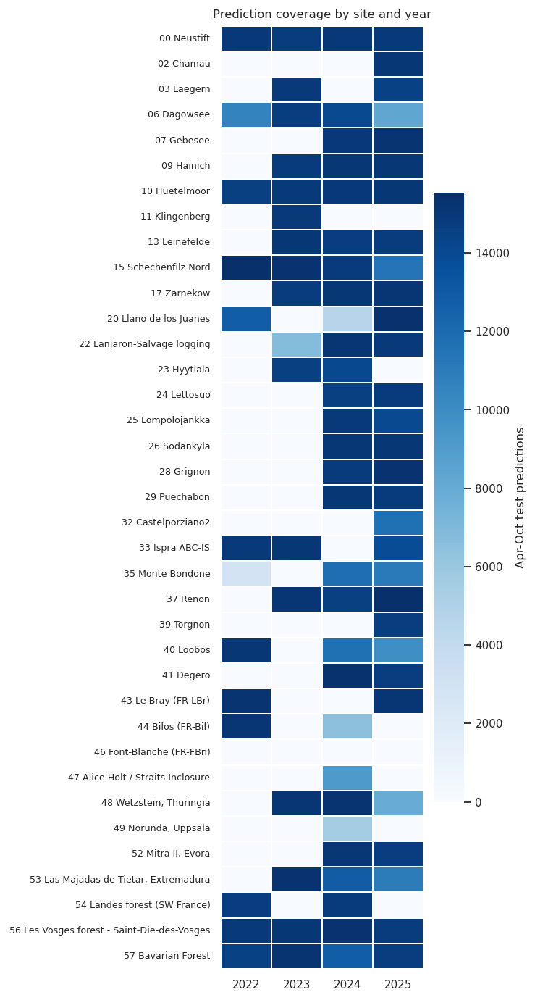

/home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/figures/generated/fig3_worldcover37_xgb_cap20000_apr_oct/worldcover37_xgb_cap20000_apr_oct_coverage.png


In [6]:
count_mat = (
    pred.groupby(["site_id", "year"], as_index=False)
    .size()
    .pivot(index="site_id", columns="year", values="size")
    .reindex(site_order)
    .fillna(0)
)
count_mat.index = site_meta.set_index("site_id").loc[site_order, "site_label"]

fig, ax = plt.subplots(figsize=(5.6, 10.5), constrained_layout=True)
sns.heatmap(
    count_mat,
    ax=ax,
    cmap="Blues",
    linewidths=0.25,
    linecolor="white",
    cbar_kws={"label": "Apr-Oct test predictions"},
)
ax.set_title("Prediction coverage by site and year")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=7)
coverage_png = FIG_DIR / "worldcover37_xgb_cap20000_apr_oct_coverage.png"
fig.savefig(coverage_png, bbox_inches="tight")
plt.show()
print(coverage_png)


## Per-site time series pages


In [7]:
trait_colors = {
    "LAI": "#1b7837",
    "LMA": "#5aae61",
    "Nitrogen": "#2166ac",
    "Chlorophyll": "#d6604d",
    "Lignin": "#762a83",
}

def plot_site(site_id, show=False):
    info = site_meta.loc[site_meta["site_id"] == site_id].iloc[0]
    site_label = info["site_label"]
    site_daily = daily[daily["site_id"] == site_id].copy()
    fig, axes = plt.subplots(len(TRAITS), 1, figsize=(9.0, 7.0), sharex=True, constrained_layout=True)
    fig.suptitle(f"{site_label} | XGB cap20000 Apr-Oct test predictions", y=1.02, fontsize=12)
    for ax, trait in zip(axes, TRAITS):
        sub = site_daily[site_daily["trait"] == trait].sort_values("date")
        color = trait_colors[trait]
        if sub.empty:
            ax.text(0.5, 0.5, "No Apr-Oct test samples", ha="center", va="center", transform=ax.transAxes)
            ax.set_axis_off()
            continue
        ax.plot(sub["date"], sub["true_median"], color=color, lw=1.5, marker="o", ms=2.5, label="Observed median")
        ax.plot(sub["date"], sub["pred_median"], color="#222222", lw=1.2, marker="s", ms=2.2, label="Predicted median")
        ax.fill_between(sub["date"], sub["true_q25"], sub["true_q75"], color=color, alpha=0.12, linewidth=0)
        ax.fill_between(sub["date"], sub["pred_q25"], sub["pred_q75"], color="#222222", alpha=0.08, linewidth=0)
        ax.set_ylabel(trait, rotation=0, ha="right", va="center")
        ax.grid(True, alpha=0.25)
        m = metrics[(metrics["site_id"] == site_id) & (metrics["trait"] == trait)].iloc[0]
        label = f"n={int(m['n_valid'])}"
        if np.isfinite(m["r2"]):
            label += f", R2={m['r2']:.2f}"
        if np.isfinite(m["nrmse_pct"]):
            label += f", nRMSE={m['nrmse_pct']:.1f}%"
        ax.text(0.99, 0.82, label, transform=ax.transAxes, ha="right", va="top", fontsize=8)
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.98, 1.02), frameon=False, ncol=2)
    out = FIG_DIR / f"site_{int(site_id):02d}_xgb_cap20000_apr_oct_timeseries.png"
    fig.savefig(out, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return out

site_figures = [plot_site(site_id, show=False) for site_id in site_order]
print(f"Wrote {len(site_figures)} per-site figures to {FIG_DIR}")


Wrote 37 per-site figures to /home/chaonan.ji/data/projects/ecospectra/docs/paper1_perspective/figures/generated/fig3_worldcover37_xgb_cap20000_apr_oct


## All 37 site figures


### 00 Neustift

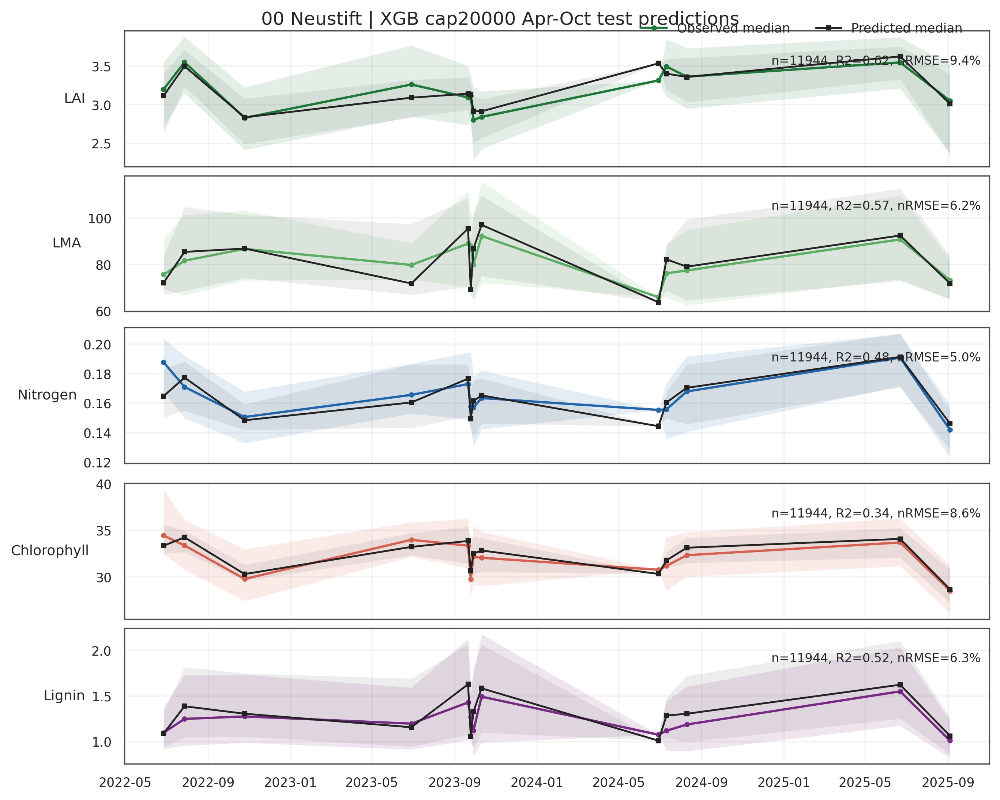

### 02 Chamau

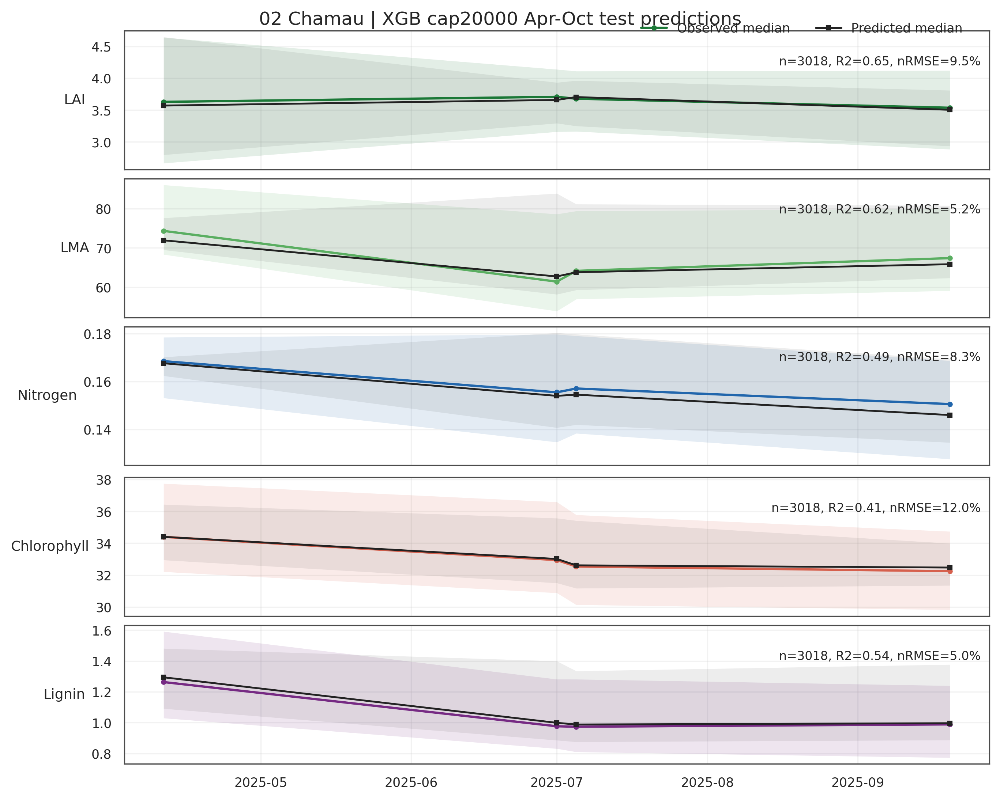

### 03 Laegern

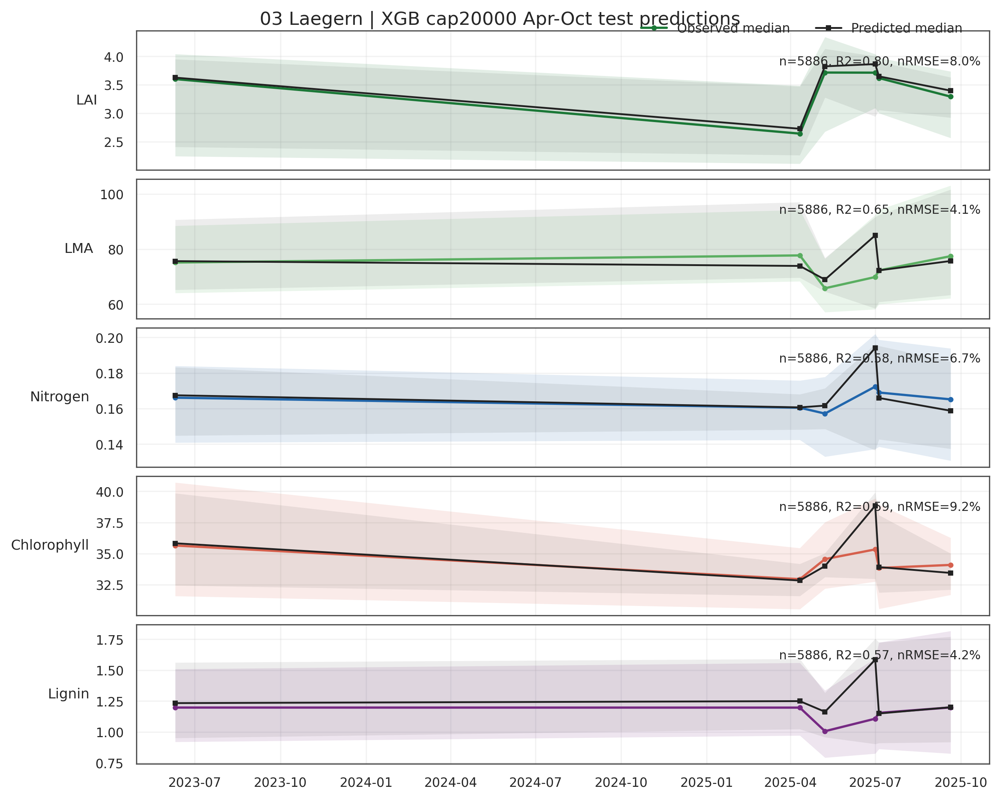

### 06 Dagowsee

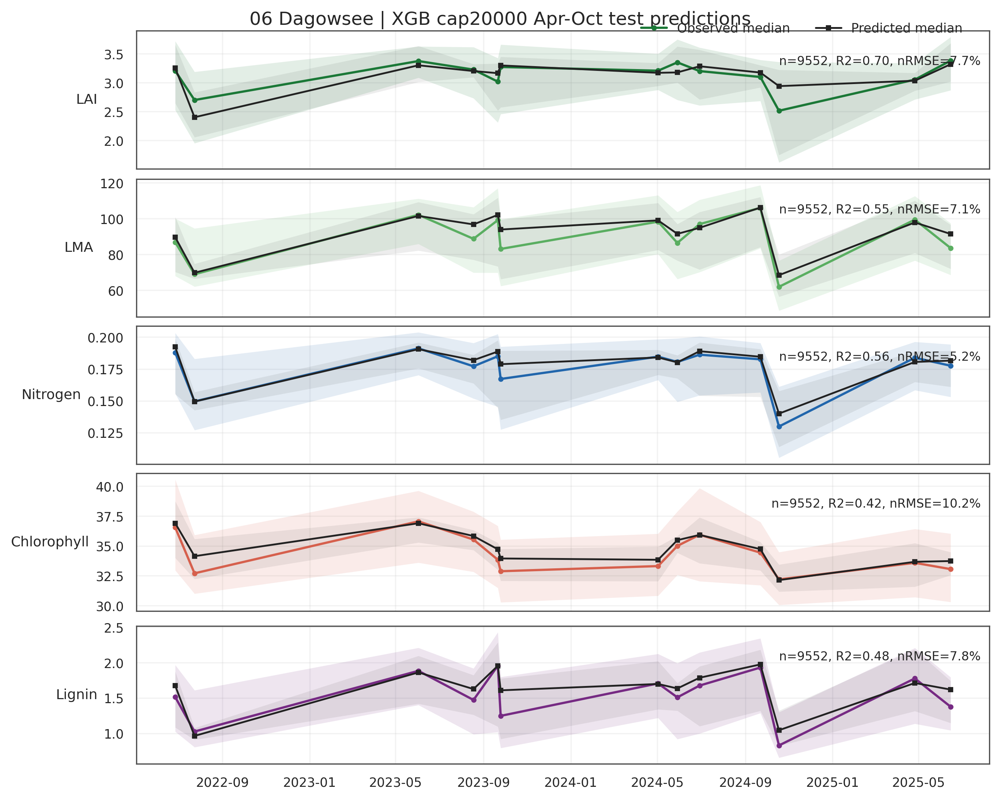

### 07 Gebesee

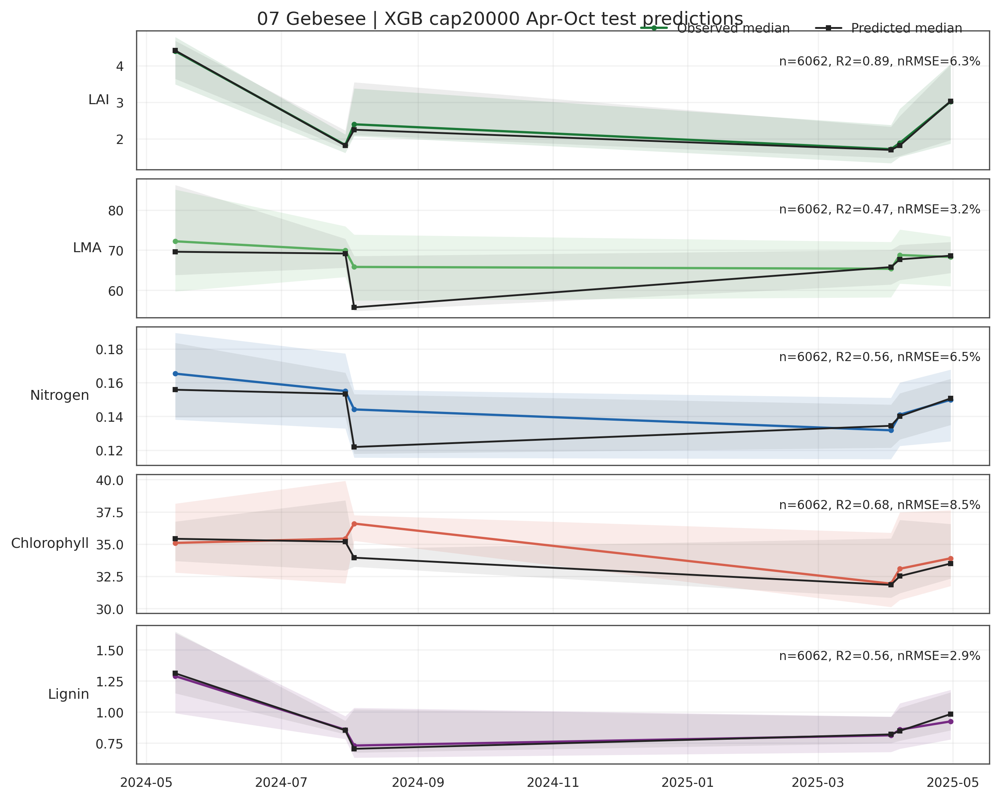

### 09 Hainich

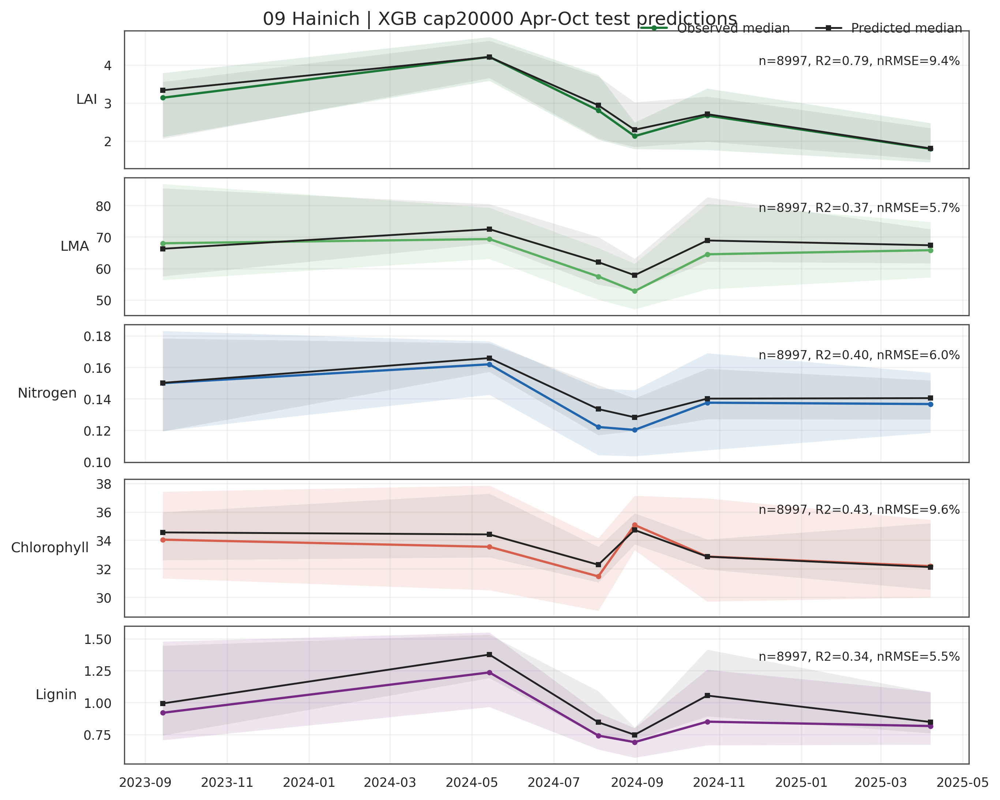

### 10 Huetelmoor

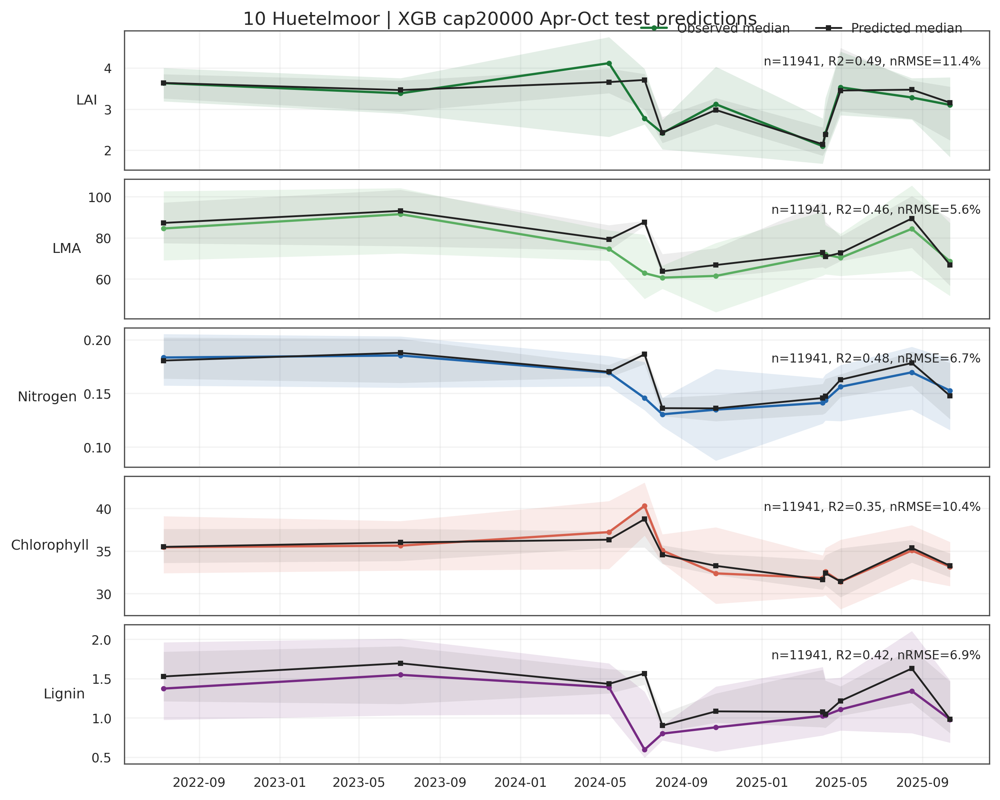

### 11 Klingenberg

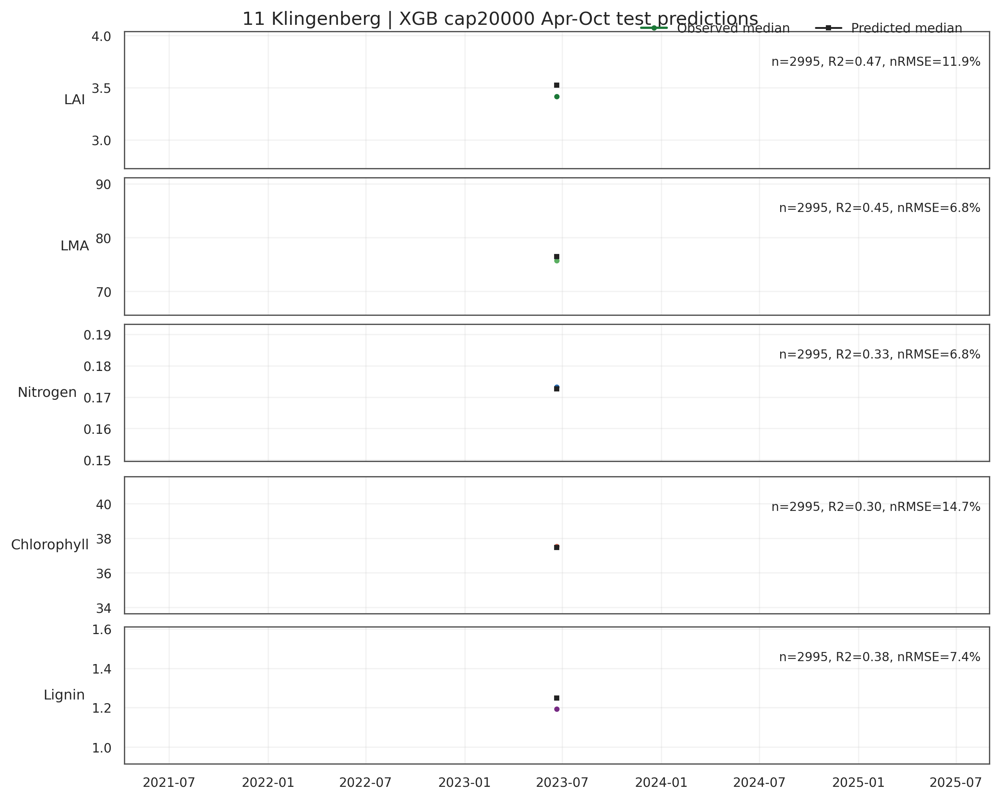

### 13 Leinefelde

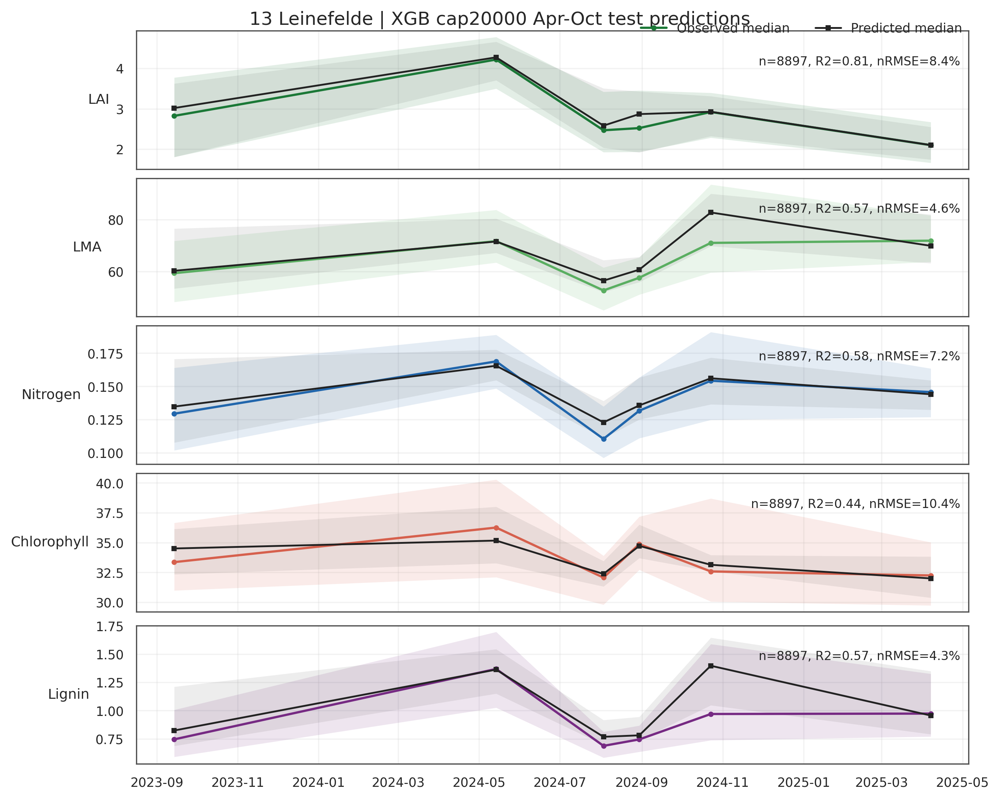

### 15 Schechenfilz Nord

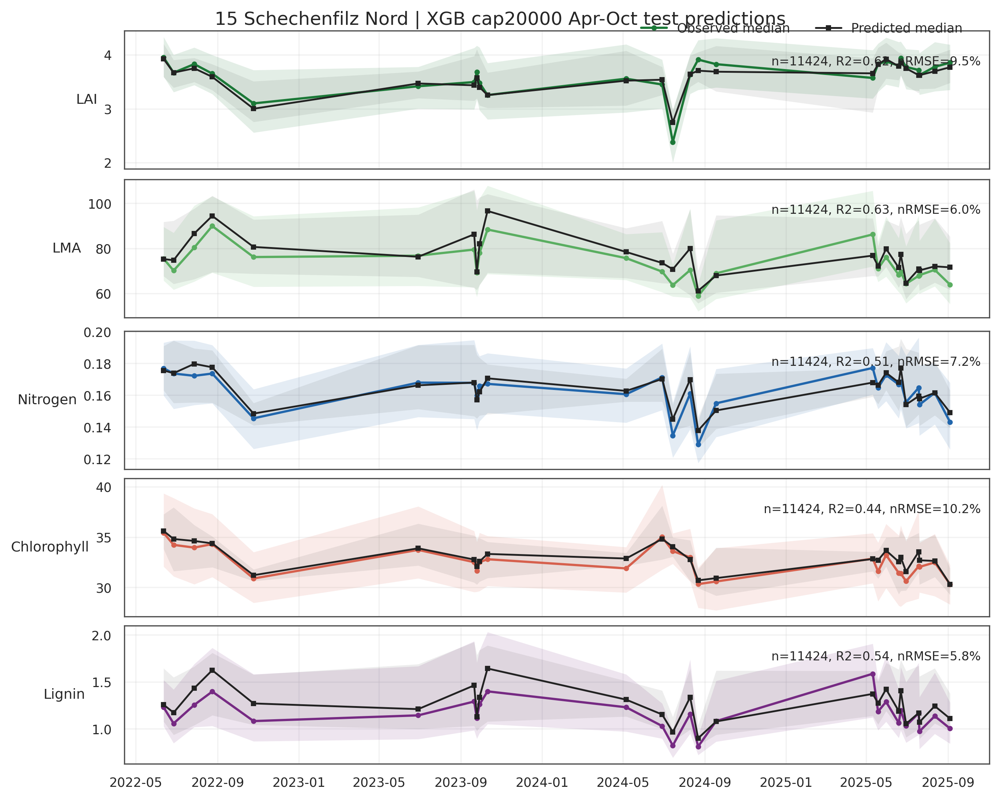

### 17 Zarnekow

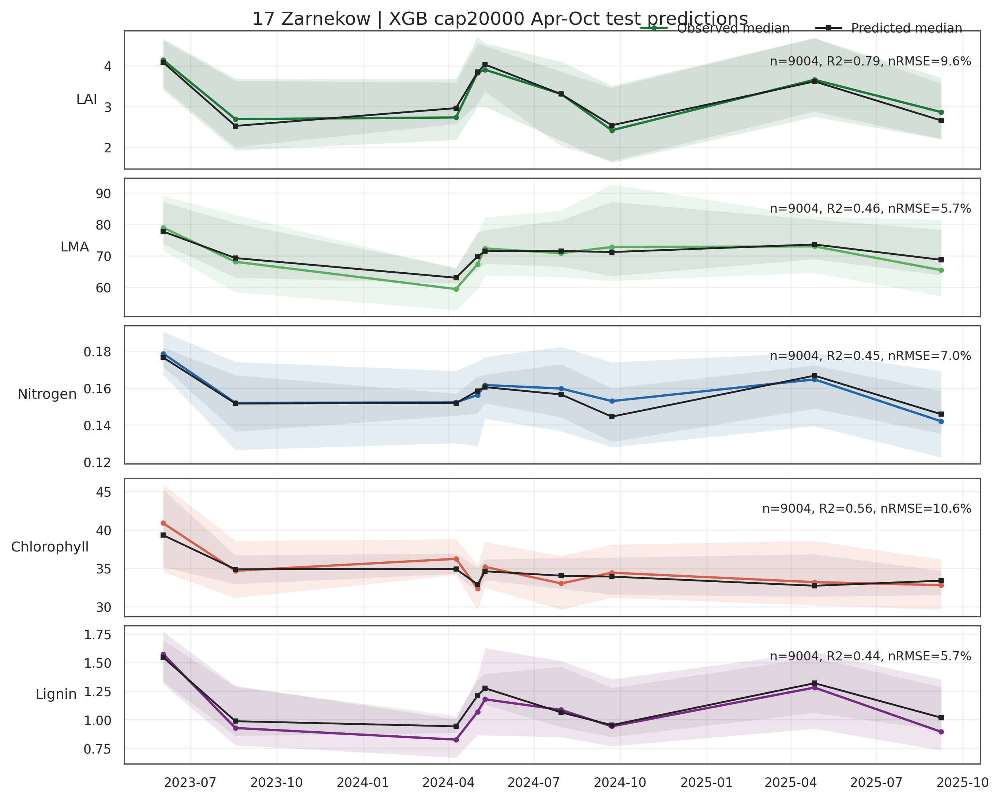

### 20 Llano de los Juanes

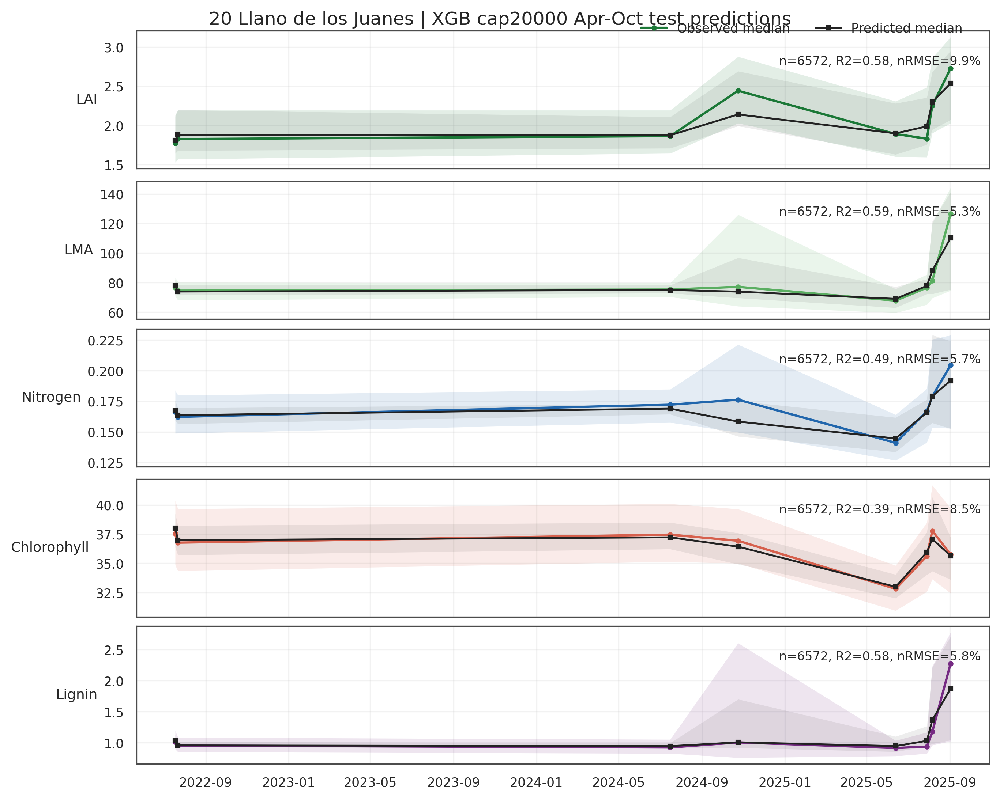

### 22 Lanjaron-Salvage logging

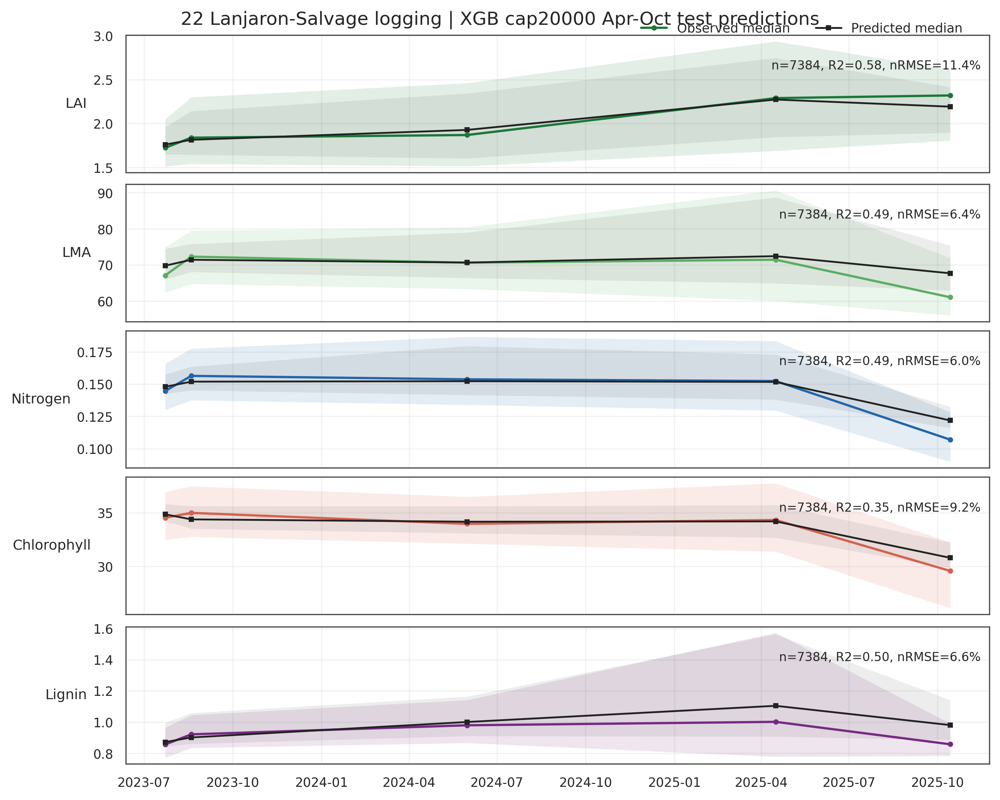

### 23 Hyytiala

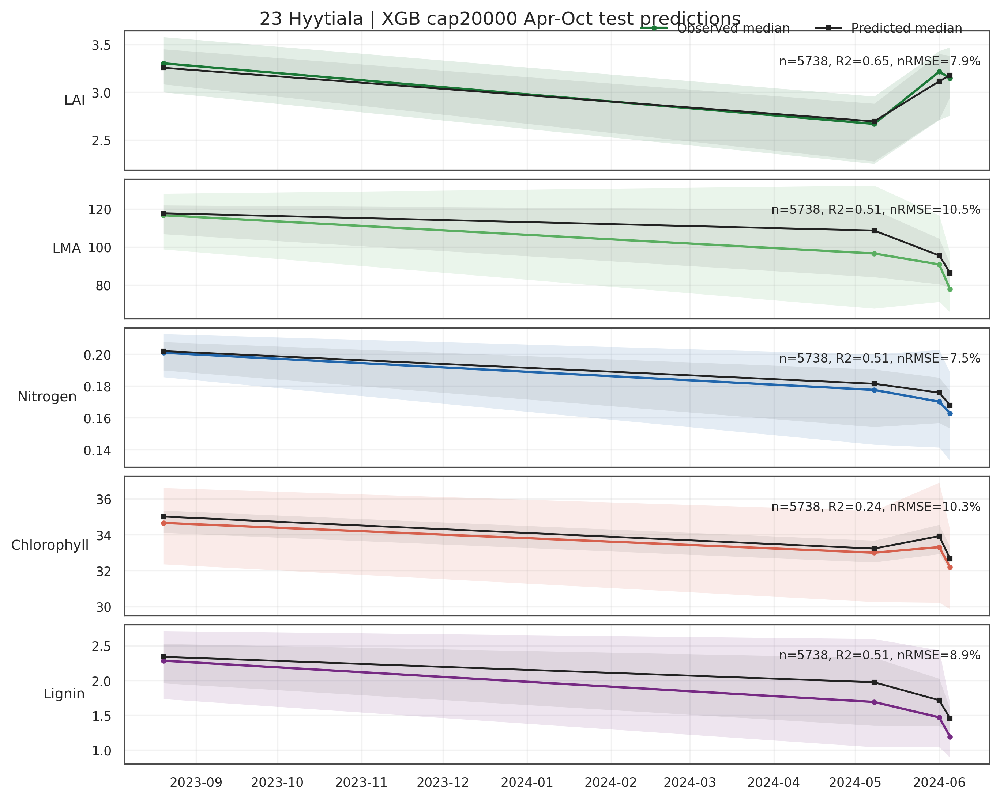

### 24 Lettosuo

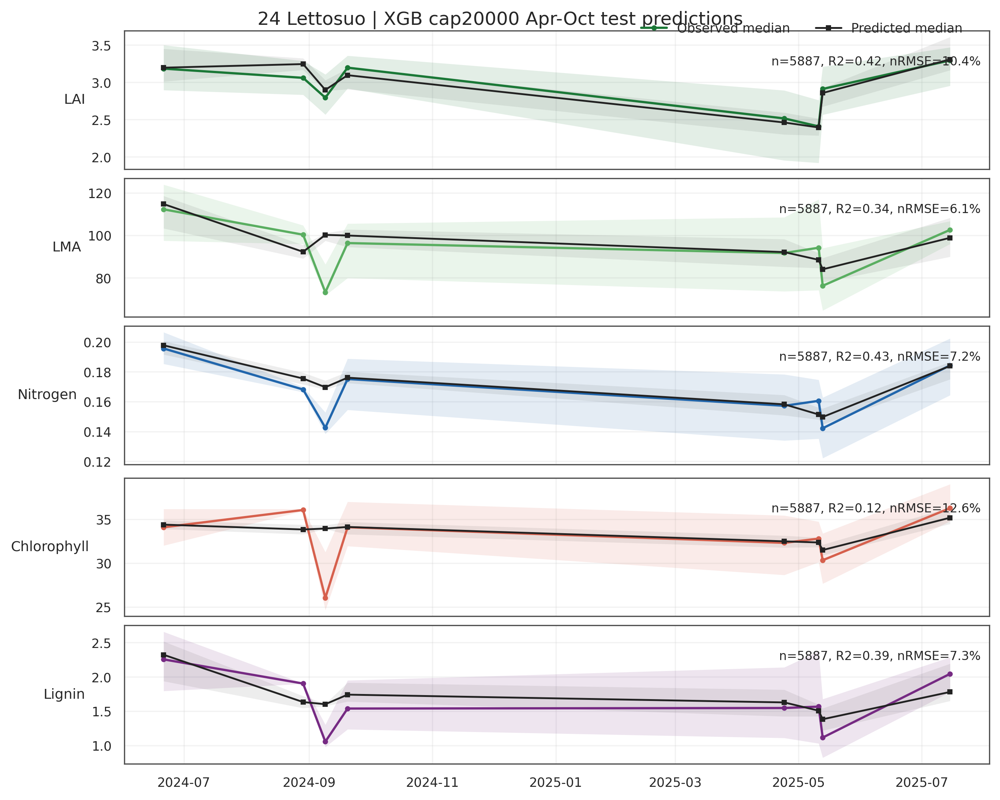

### 25 Lompolojankka

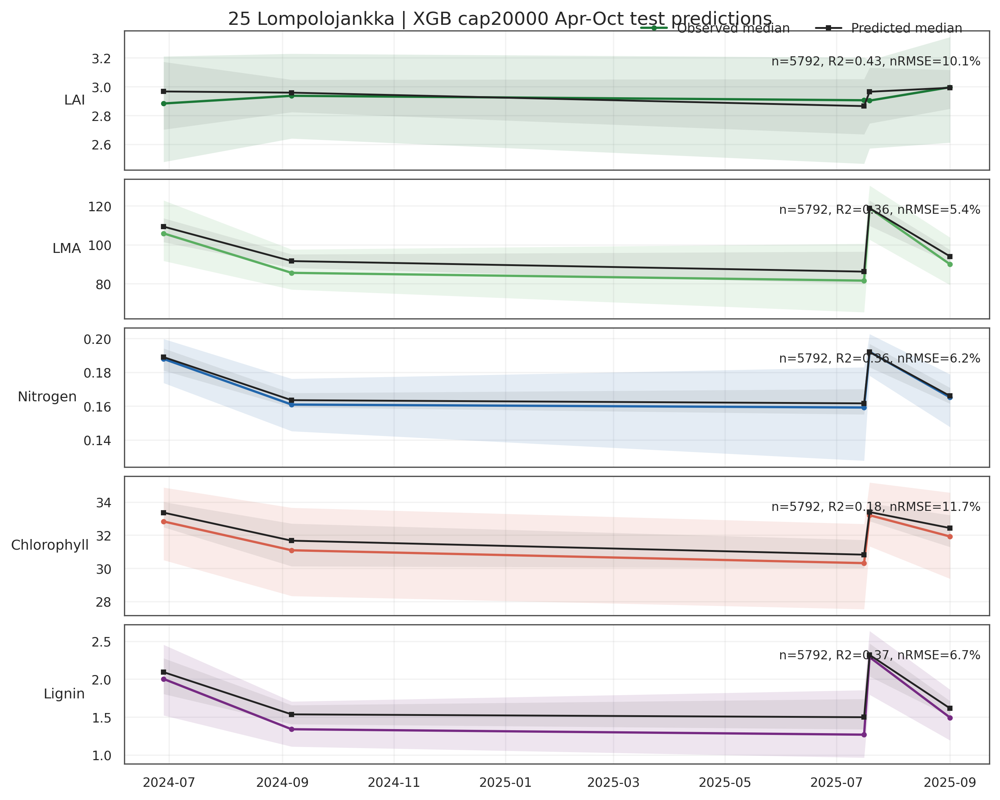

### 26 Sodankyla

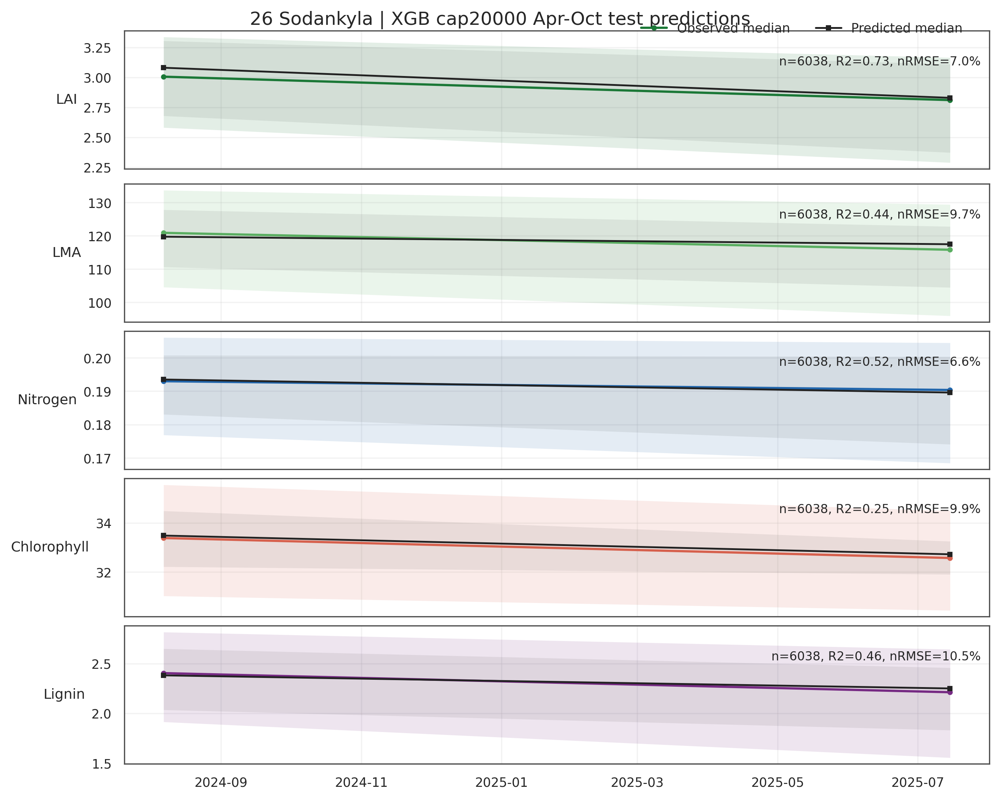

### 28 Grignon

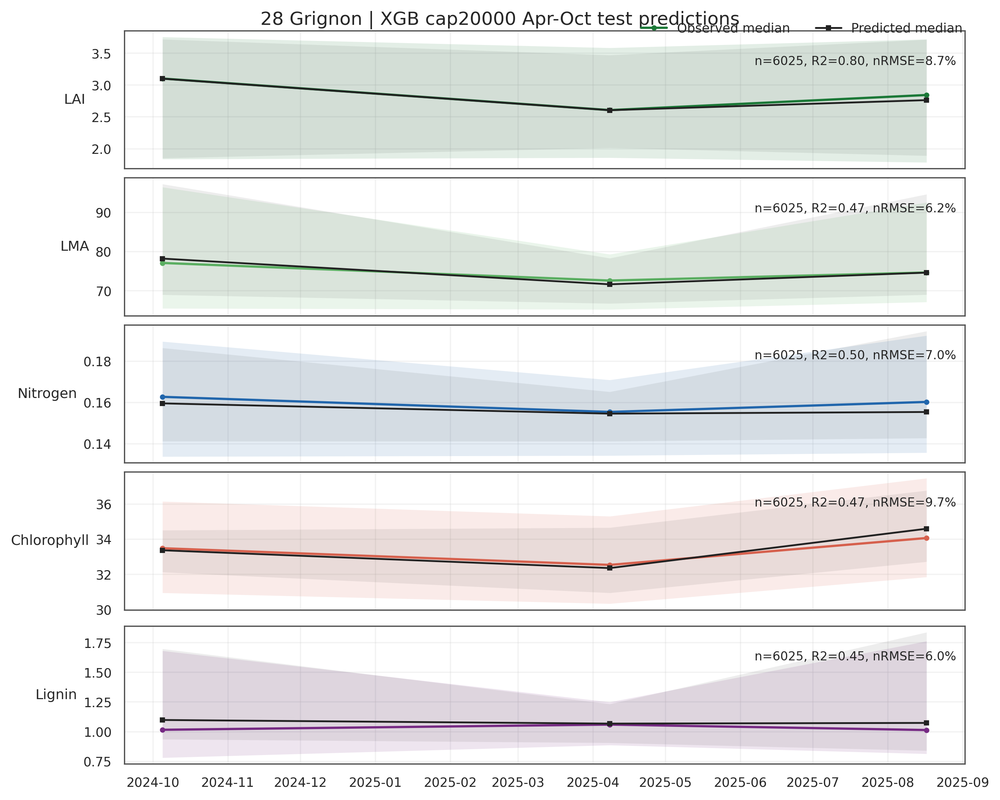

### 29 Puechabon

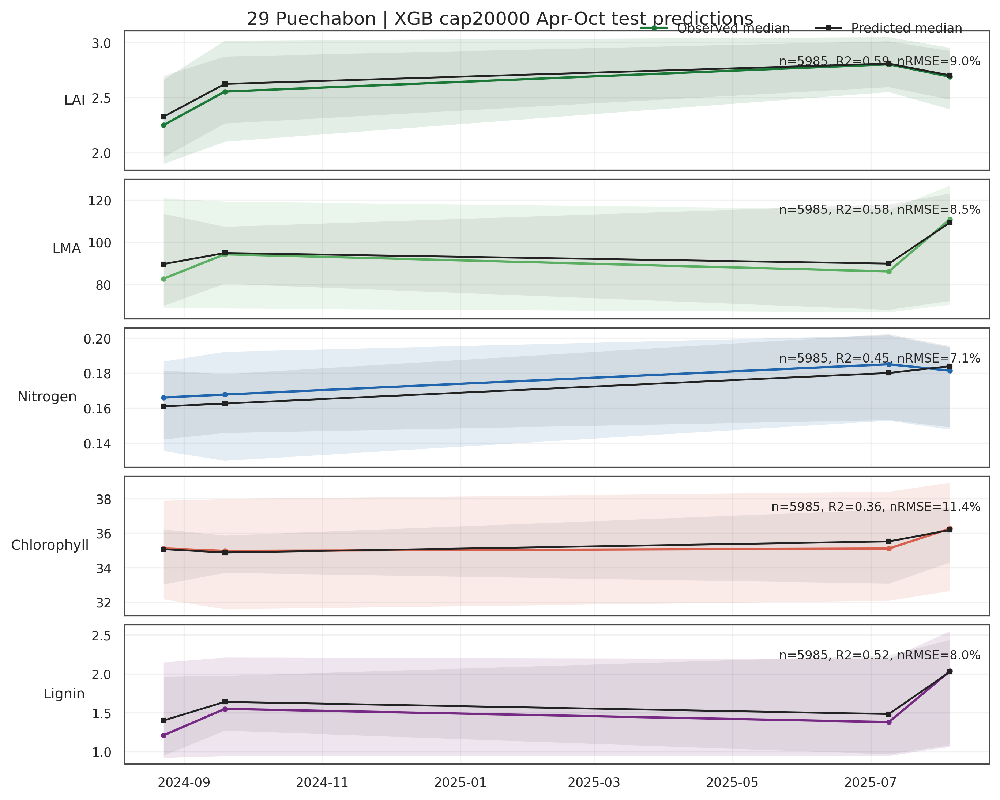

### 32 Castelporziano2

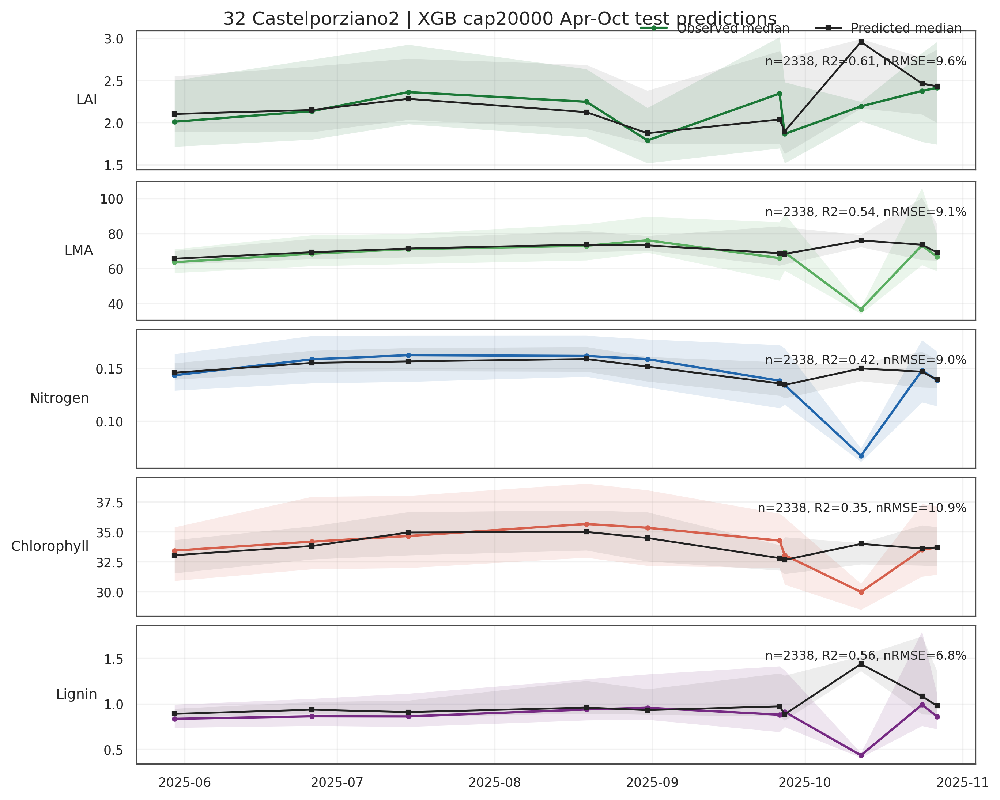

### 33 Ispra ABC-IS

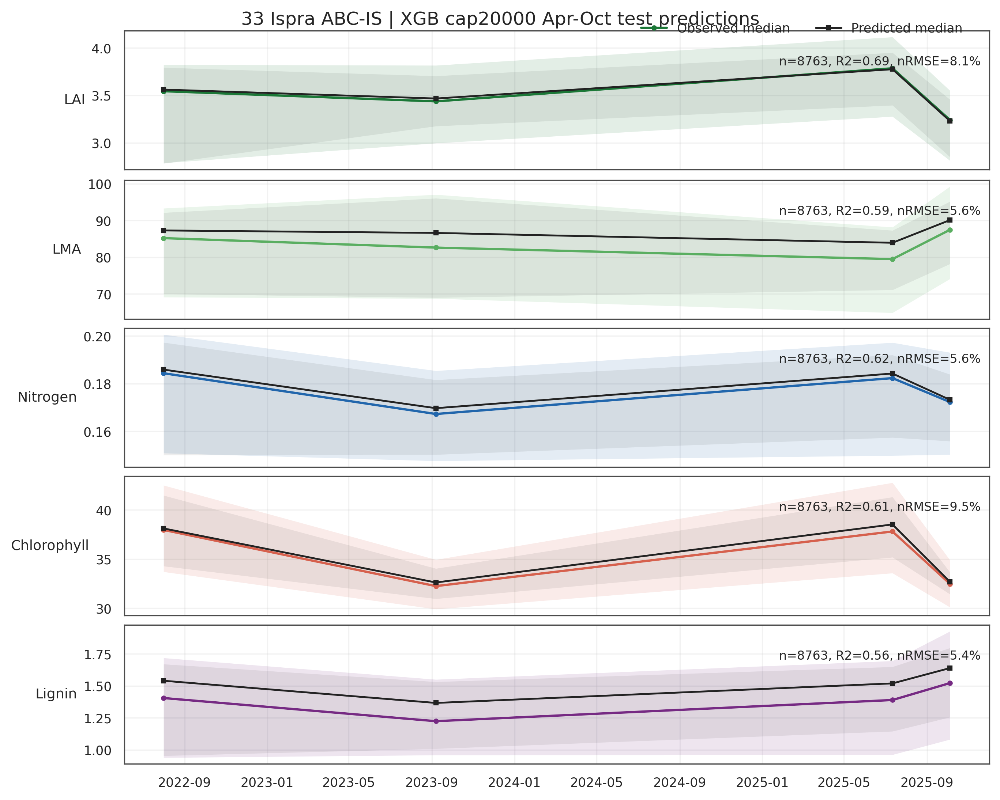

### 35 Monte Bondone

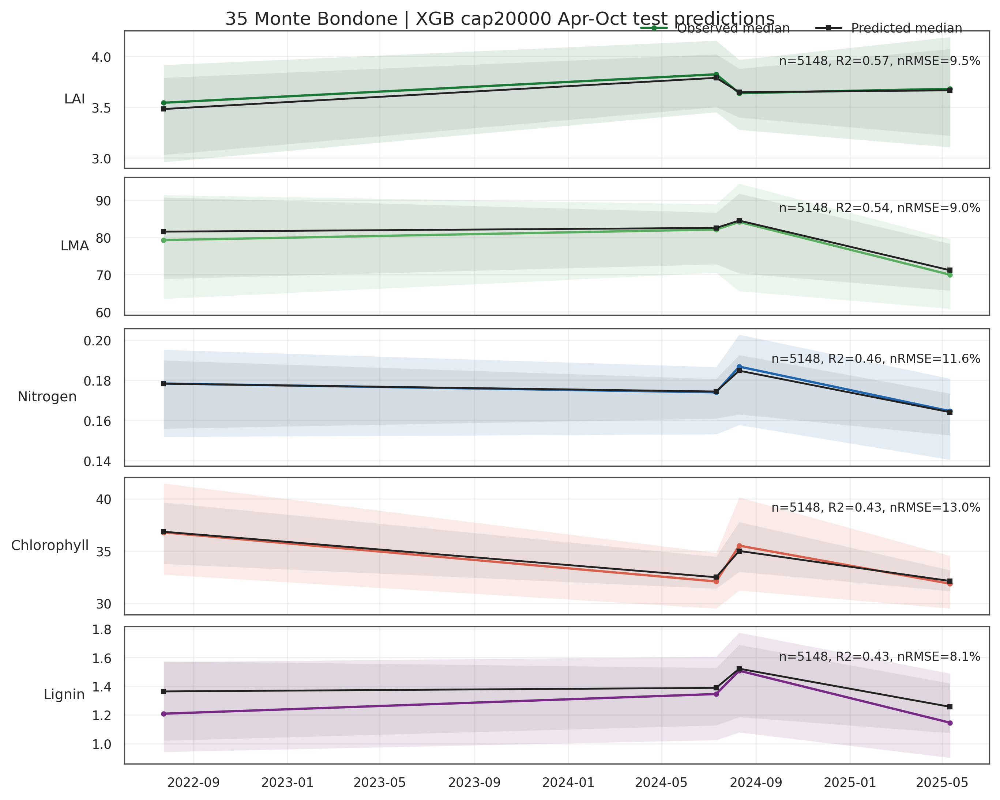

### 37 Renon

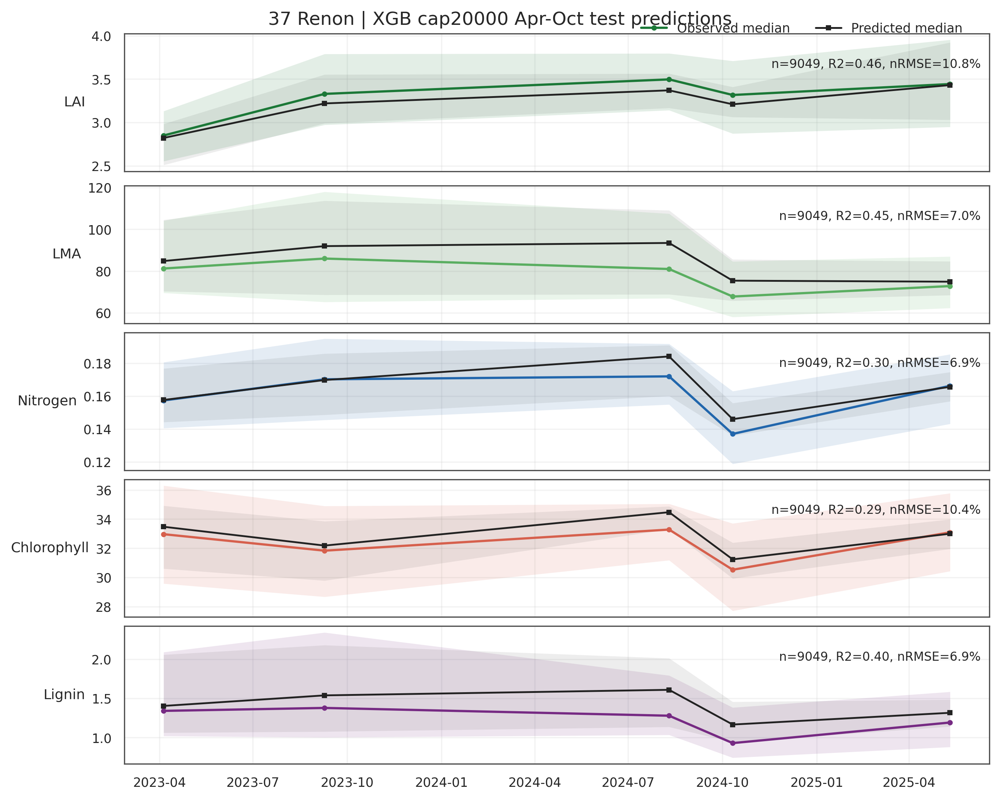

### 39 Torgnon

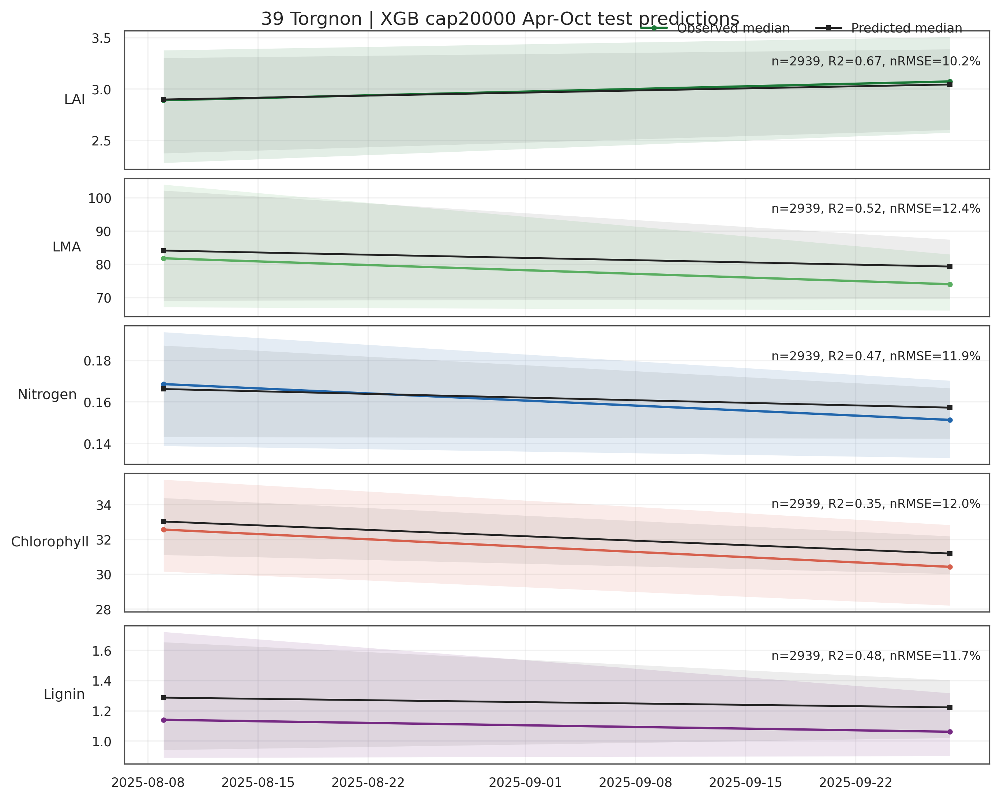

### 40 Loobos

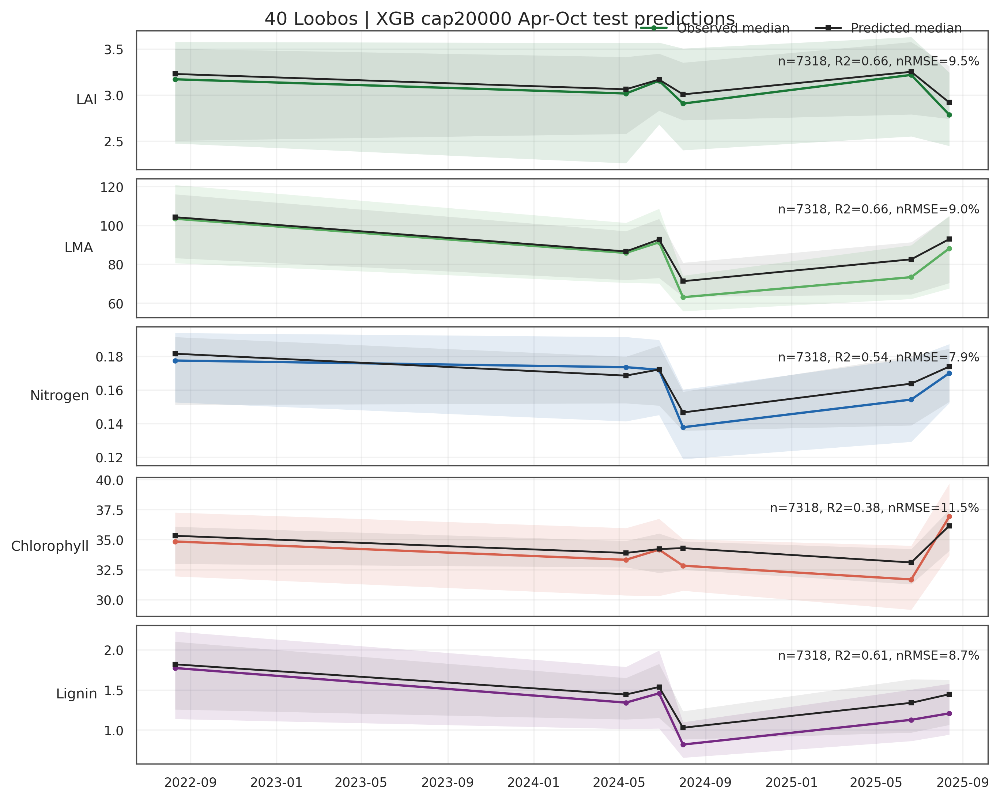

### 41 Degero

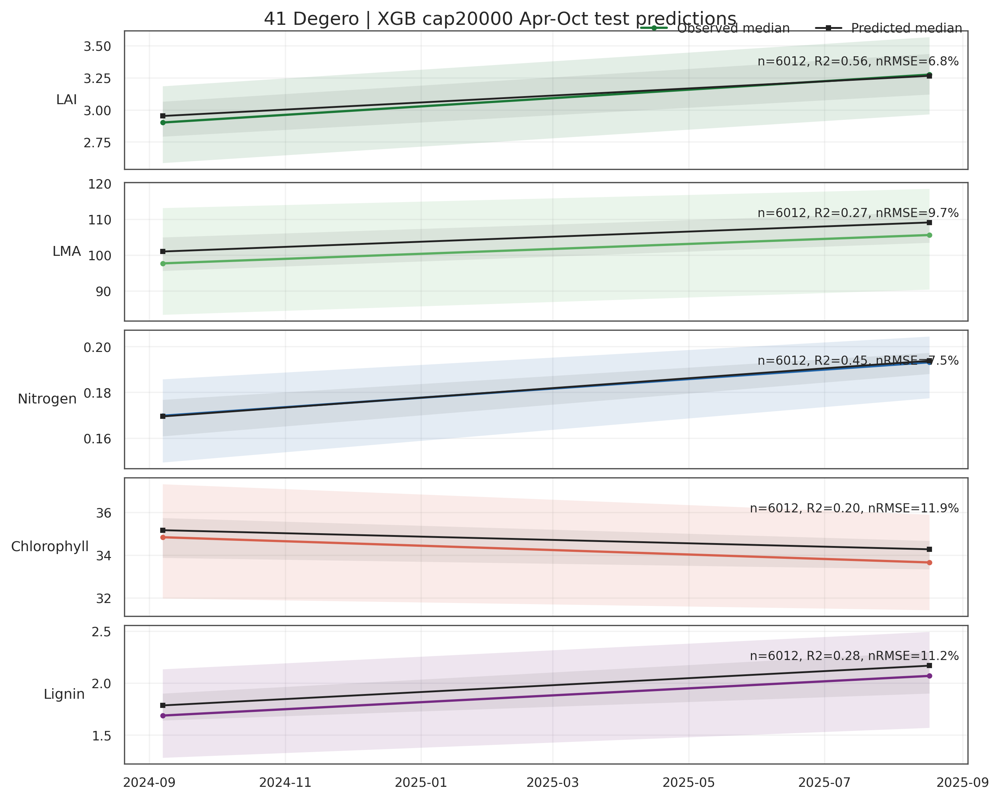

### 43 Le Bray (FR-LBr)

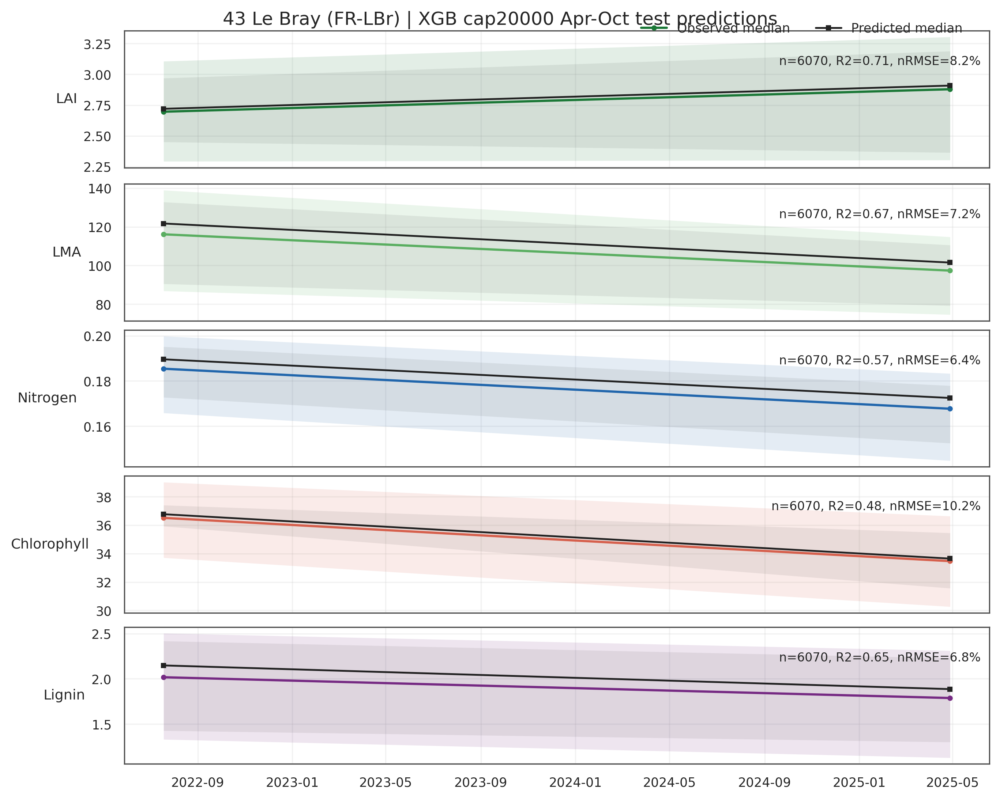

### 44 Bilos (FR-Bil)

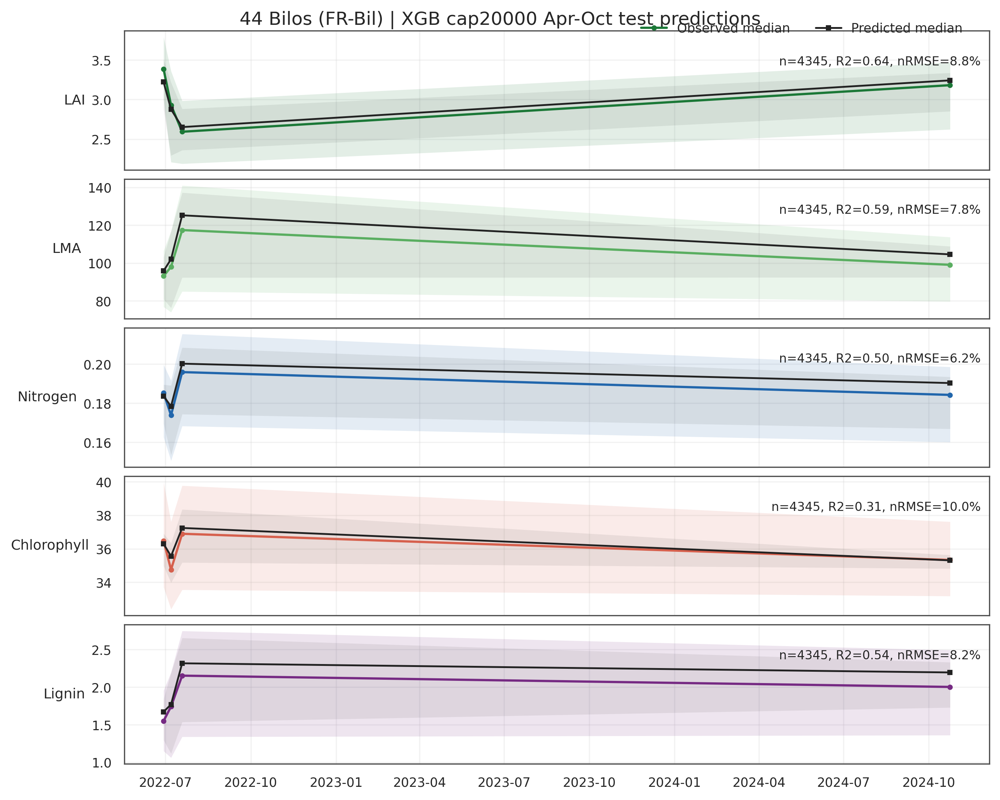

### 46 Font-Blanche (FR-FBn)

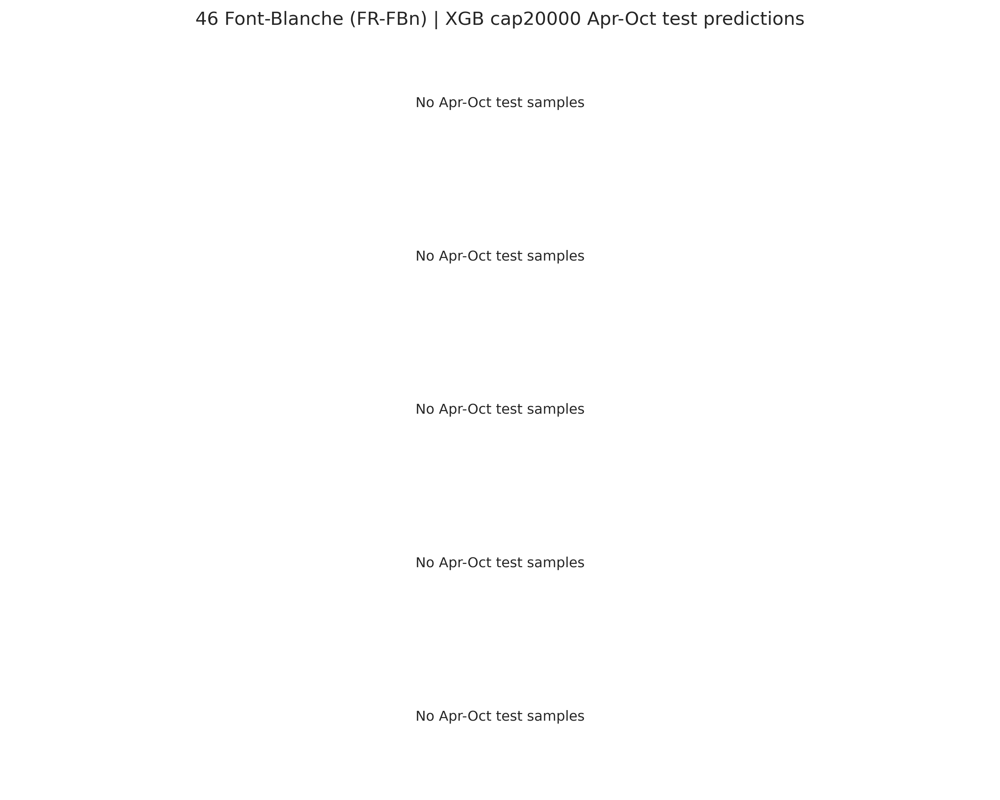

### 47 Alice Holt / Straits Inclosure

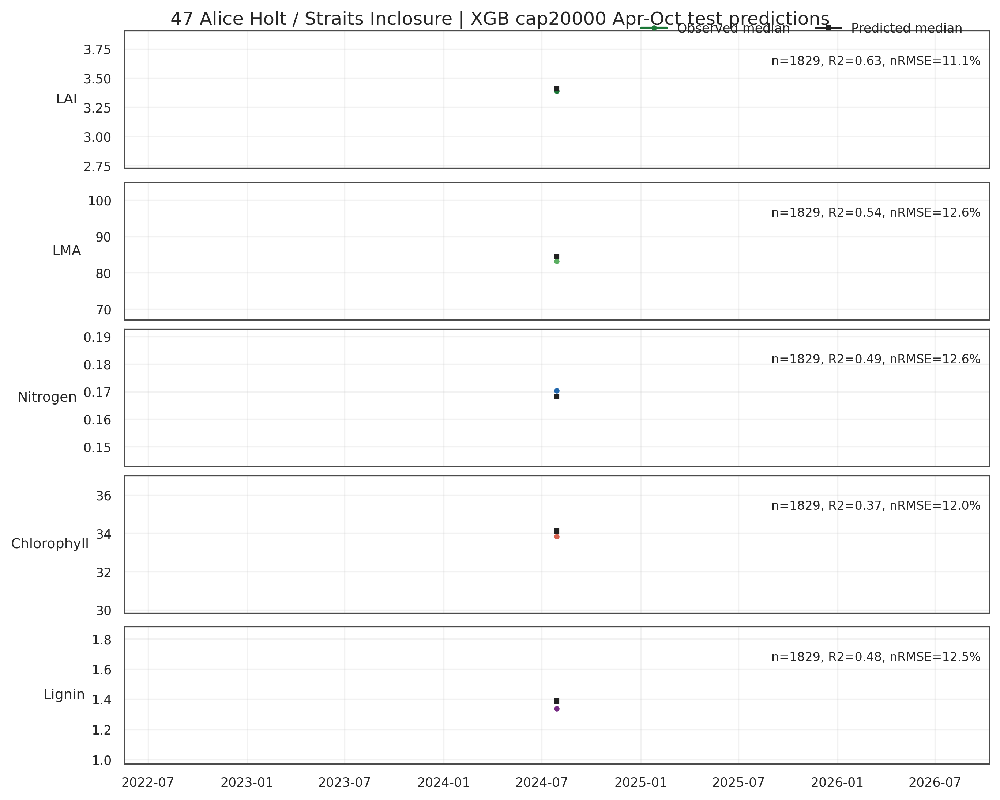

### 48 Wetzstein, Thuringia

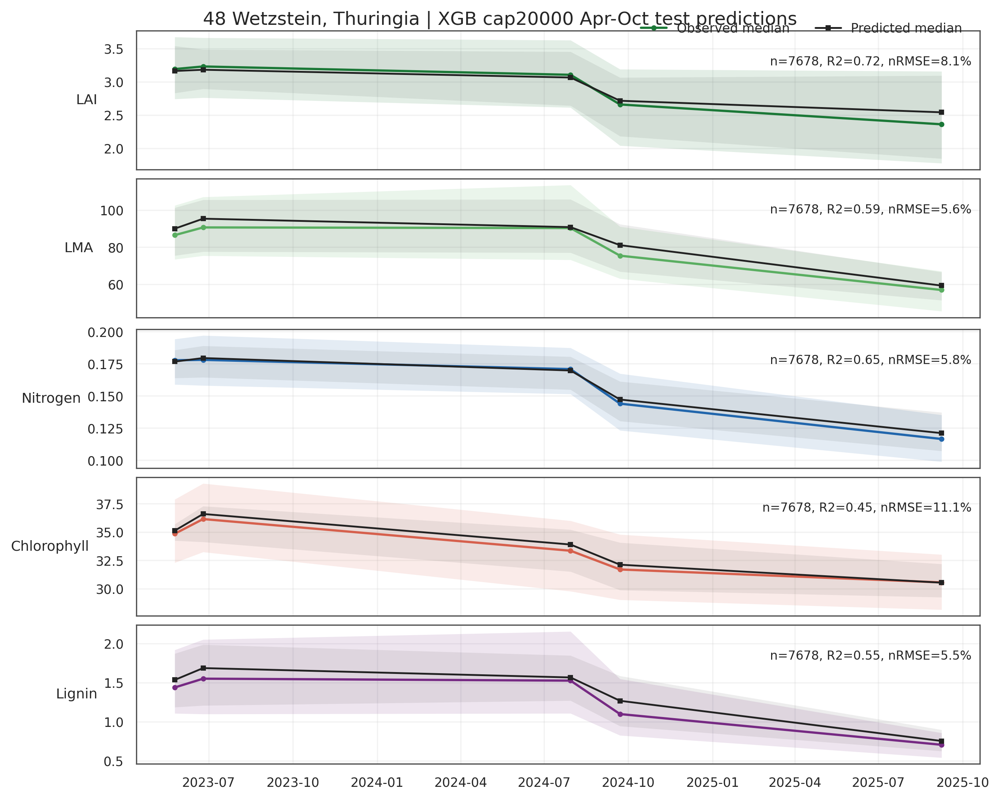

### 49 Norunda, Uppsala

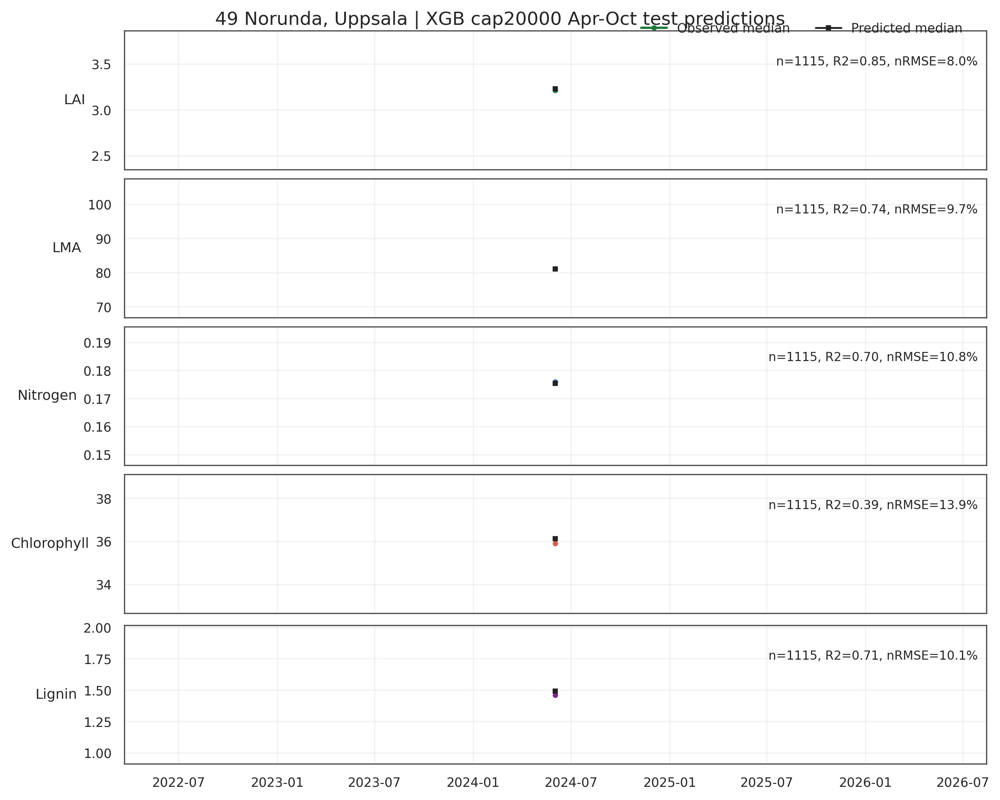

### 52 Mitra II, Evora

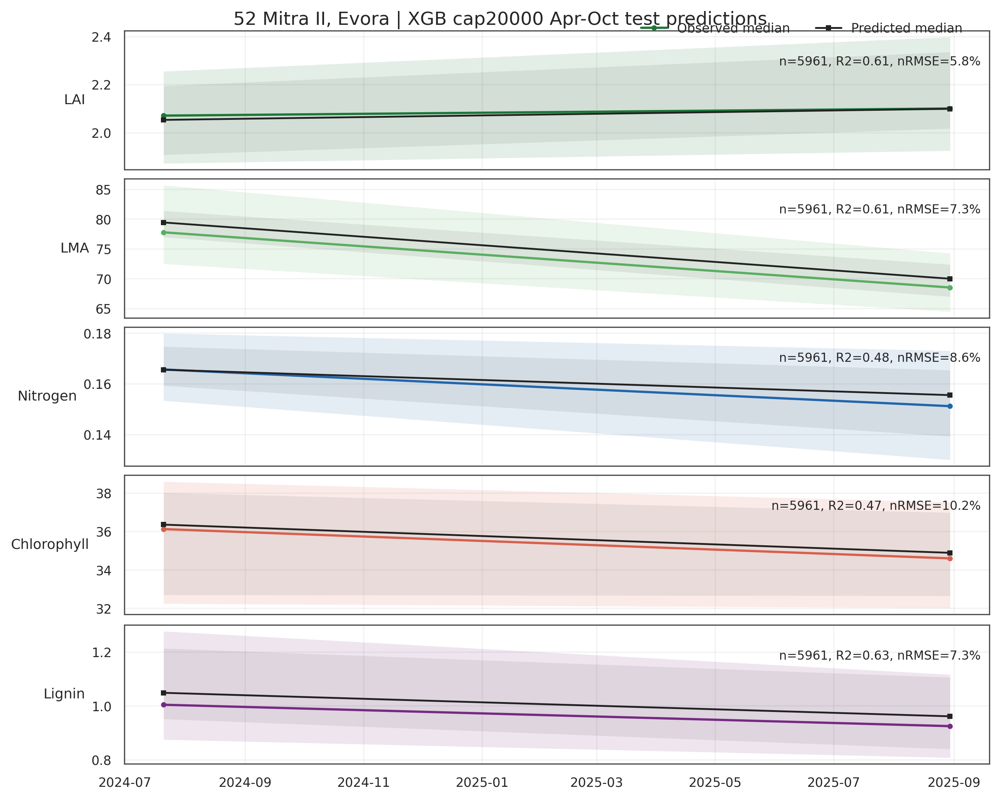

### 53 Las Majadas de Tietar, Extremadura

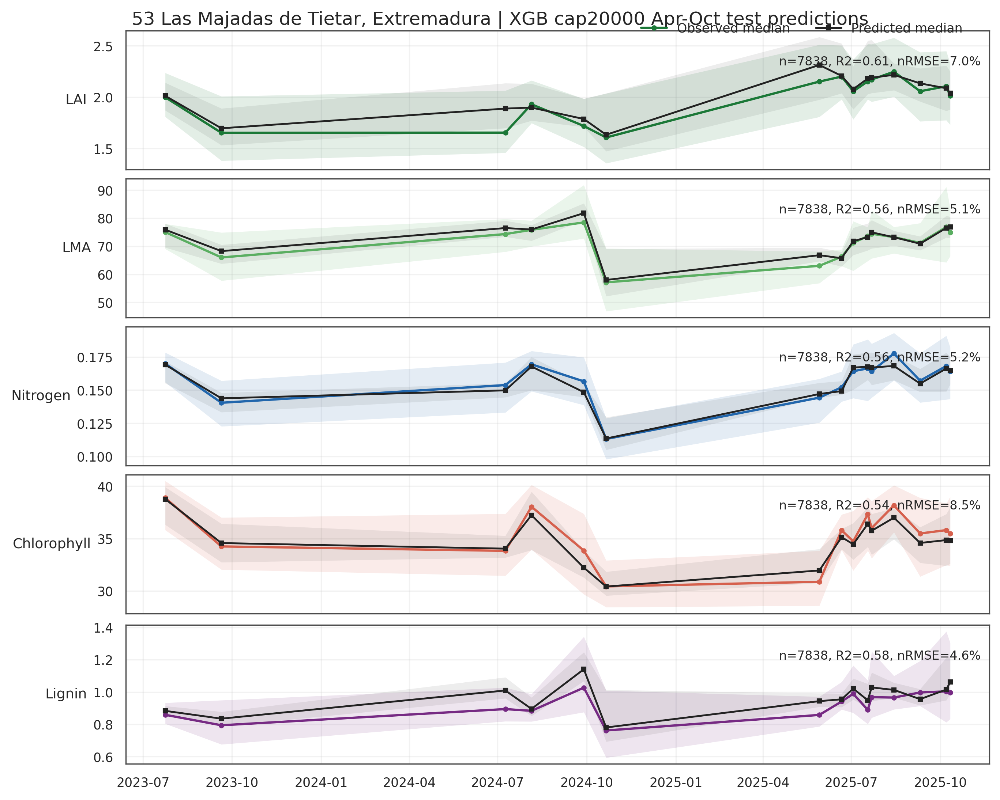

### 54 Landes forest (SW France)

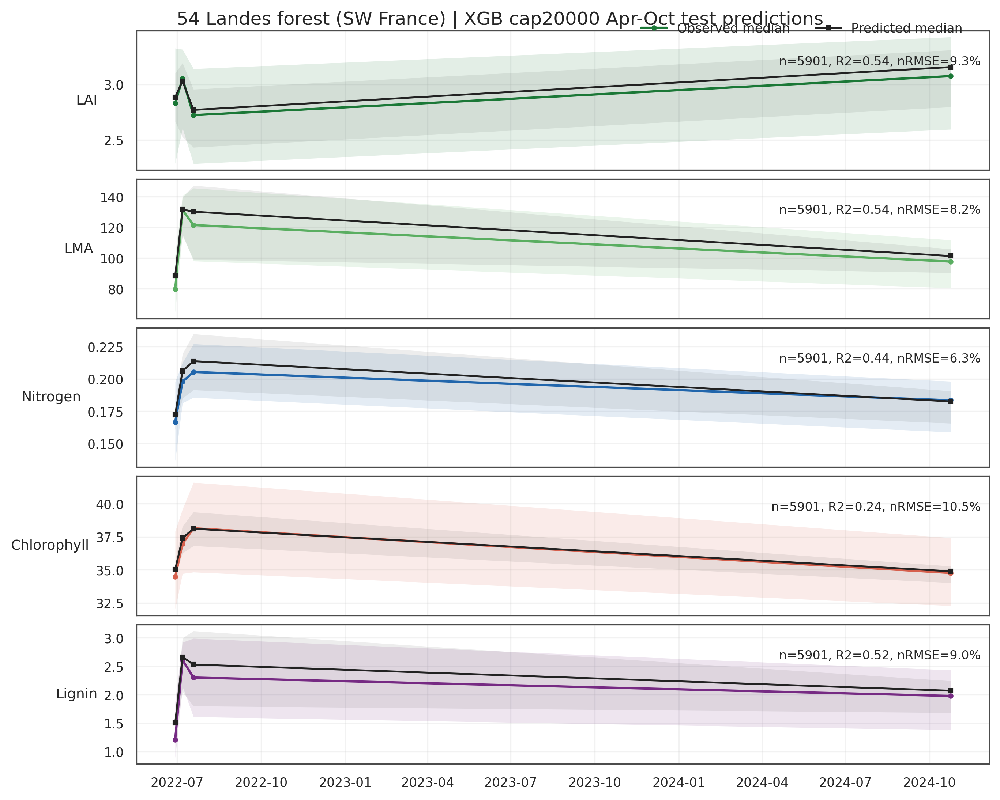

### 56 Les Vosges forest - Saint-Die-des-Vosges

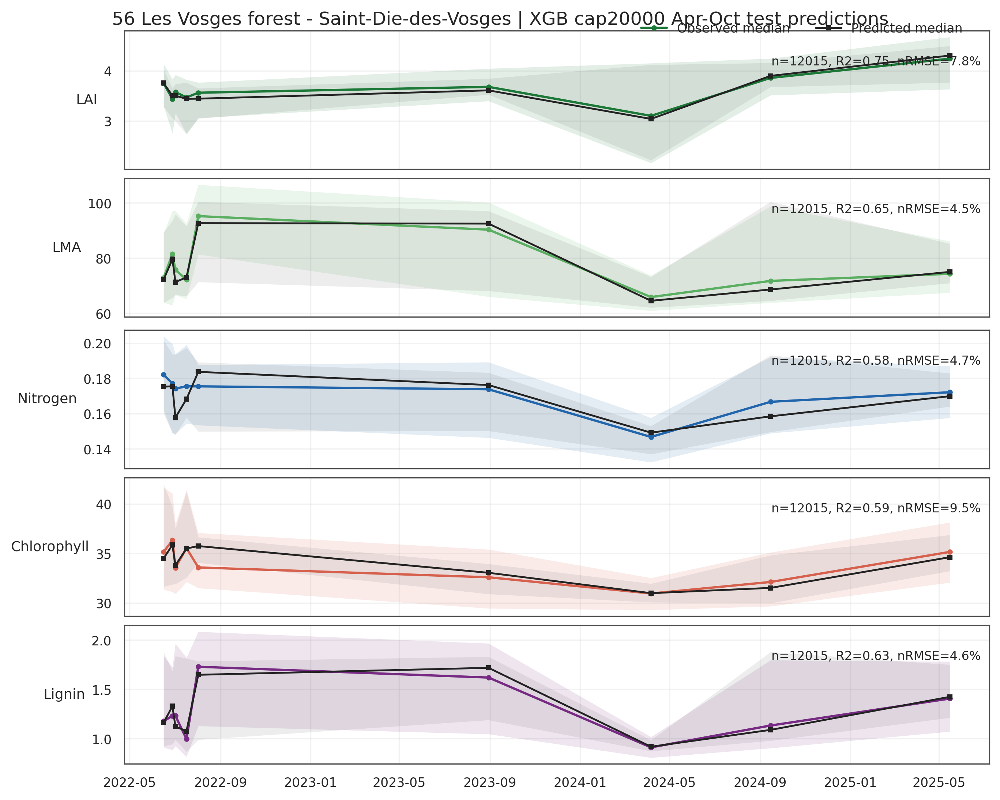

### 57 Bavarian Forest

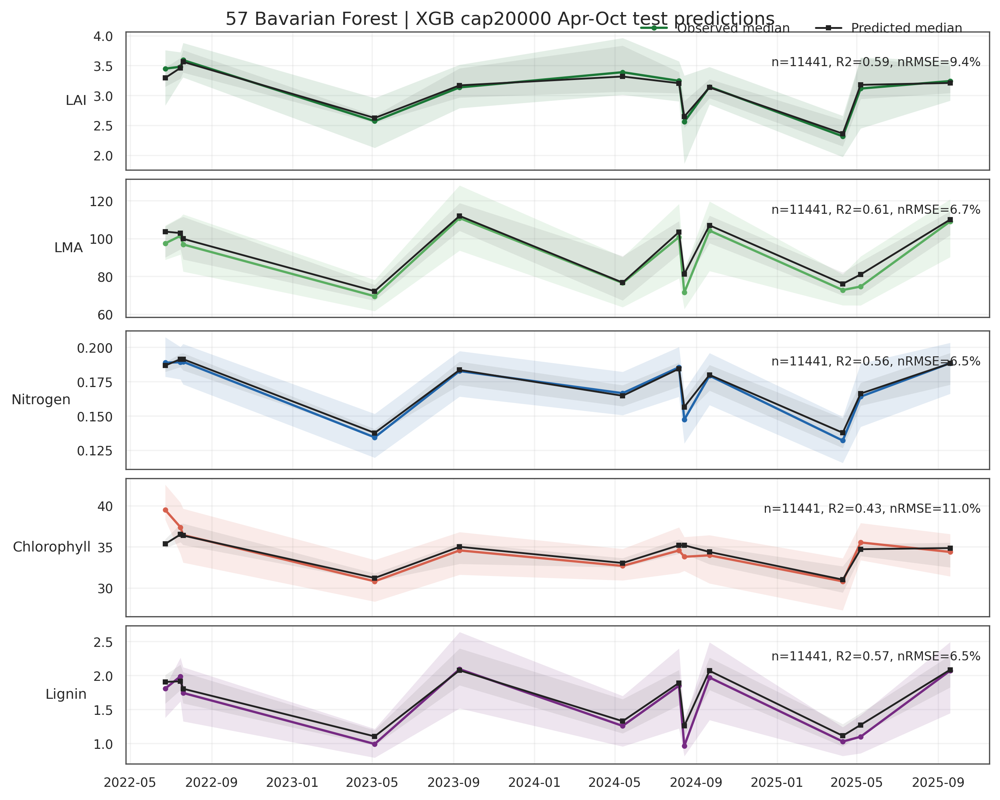

In [8]:
for site_id, fig_path in zip(site_order, site_figures):
    label = site_meta.loc[site_meta["site_id"] == site_id, "site_label"].iloc[0]
    display(Markdown(f"### {label}"))
    display(Image(filename=str(fig_path)))
